# Demonstration — Zonal Penalty Framework

Curated extract of `flp_definitive_GA_ALNS_fixed full results 8.ipynb`, the run every reported figure comes from. Cells and outputs are unmodified; only the ordering and these headings are added.

*No kernel required — every output shown was produced by that run.*

## Shot 1 — Configuration

Grid, zone radii, recovery budget and the fixed seed. Everything after this reproduces from these values.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  CONTROL PANEL — every tunable parameter for every phase of the pipeline
# ═══════════════════════════════════════════════════════════════════════════
#  Phase map:
#    Phase 1  run_nsga2()            -> GA / NSGA-II group
#    Phase 2  evaluate_layout(repair=True) -> Layout repair + Phase widths
#    Phase 3  connect_deep_polish / ensure_full_connectivity -> Layout repair
#    Phase 4  zpf_recovery()         -> ZPF disruption group
#    Phase 5  simulate_layout()      -> Simulation & power group
#    Phase 6  plot_zpf_sequence()    -> Phase widths
# ═══════════════════════════════════════════════════════════════════════════
import numpy as np

# ── FACTORY GEOMETRY & TIME ──────────────────────────────────────────────────
# Used by FactoryGrid, blf_decode (placement) and every belt-travel calculation.
GRID_W              = 70     # grid width  in cells
GRID_H              = 70     # grid height in cells
MIN_MACHINE_SPACING = 1      # clearance kept around every machine, in cells
TICK_SECONDS        = 2.0    # wall-clock seconds represented by one tick
BELT_SPEED          = 1      # ticks to traverse one 1x1 belt cell
SIM_EQ_MAX_TICKS    = 300    # Gate 2 budget; overridden by CFG below

# Power is not charged for the first CFG.POWER_GRACE_TICKS ticks of a
# simulation, letting the pipeline fill before the bill starts. The grace
# period is deliberately a FIXED TICK COUNT, not "until equilibrium": gating a
# cost on equilibrium is exploitable in the worst direction, since a layout that
# never stabilises would never start paying, and starving machines is precisely
# how a layout avoids stabilising. A fixed window cannot be manipulated by the
# layout being evaluated.
STARTUP_FREE        = True

@dataclass
class FLPConfig:
    # --- Sorting Weights ---
    WEIGHT_FEASIBILITY: float = 100.0
    WEIGHT_REVENUE: float = 0.2
    # --- Multiprocessing Toggle ---
    MULTIPROCESSING: bool = True
    N_JOBS: int = -1  # -1 uses all available cores
    # --- reproducibility --------------------------------------------------
    RANDOM_SEED: int = 12          # seeds population init, crossover, mutation,
                                    # AND (deterministically, per genotype) the
                                    # ZPF disruption-recovery search below.

    # --- GA (NSGA-II) -------------------------------------------------------
    POP_SIZE: int = 200
    NGEN: int = 50
    CXPB: float = 0.7              # crossover probability
    MUTPB: float = 0.2             # mutation probability
    MAX_MACHINES: int = 160        # hard cap on machines/individual
    # (minimise build_cost, maximise terminal_rate, minimise MHC)
    #
    # Regret used to be a fourth objective here, permanently pinned at 0.0
    # because it is BY DESIGN a post-bombing quantity: Phase 1 generates
    # layouts, Phase 4 bombs them, and only then does regret exist. Declaring
    # it during evolution did not make the search resilience-aware -- it just
    # handed NSGA-II a constant axis on which every individual ties, which
    # inflates the non-dominated front and flattens crowding distance, diluting
    # selection pressure on the three objectives that are actually measured.
    # Regret is still computed and reported in Phase 4 (and, from Phase 5, also
    # against simulated throughput); it is simply no longer pretending to steer
    # a search that never sees it.
    OBJ_WEIGHTS: tuple = (-1.0, 1.0, -1.0)

    # --- ZPF disruption zone (Four-zone Euclidean model) ---------------------
    ZPF_X: int = 22
    ZPF_Y: int = 22
    ZPF_W: int = 3   # bomb footprint -- must stay completely empty
    ZPF_H: int = 3
    ZPF_R1: float = 5.0
    ZPF_R2: float = 12.0
    # Budget shared by BOTH recovery variants -- they must match or the
    # comparison measures the budget rather than the method. 300 x 5 scenarios
    # x 5 layouts = 7,500 evaluations per Phase 4.
    #
    # Prefer spending a cut on DEPTH rather than on scenarios: the regret
    # distribution is the evidence, the search depth is only how hard each
    # point in it was worked. ZPF_EARLY_STOP below makes the depth choice
    # self-justifying -- if recoveries routinely stop early, 300 is generous;
    # if they routinely run to the wall, raise it.
    ZPF_ITERATIONS: int = 300   # total recovery evaluations
    # Evaluations without improving the RECORD before a recovery gives up.
    # 0 disables. Reported per run as recovery_log["stopped_early"], so the
    # budget actually used can be quoted rather than assumed.
    ZPF_EARLY_STOP: int = 100
    ZPF_POP_SIZE:   int = 20    # NSGA-II recovery population

    # --- ZPF: keep the supply plan fixed across the disruption ----------------
    # zpf_recovery used to call derive_flow_matrix() from scratch on the
    # surviving machines. That matcher is greedy and ORDER-DEPENDENT, and
    # recovery returns `placed` in a different order (stable machines first,
    # then movable), so the pairings changed even when the bomb destroyed
    # nothing and moved nothing. Demonstrated on a 14-machine layout with a
    # crater that touched no machine at all:
    #
    #   identical machine positions : True   (0 moved, 0 destroyed)
    #   flow pairings identical     : False  (4 dropped, 4 new)
    #   routed 14 -> 12,  feasibility 100% -> 96%
    #
    # With this True the pre-bomb pairings are carried through and only the
    # BELTS are re-routed, so pre- and post-bomb are the same graph and regret
    # measures the disruption instead of a reshuffle. Flows whose endpoints did
    # not survive are dropped. Set False if you want the factory to be allowed
    # to re-plan which machine feeds which after damage -- but then pre/post
    # numbers are not directly comparable.
    ZPF_PRESERVE_FLOWS: bool = True

    # --- keep the belts the blast never touched -------------------------------
    # recover() and post_bomb_state() used to build a fresh grid and re-route
    # every flow, including the ~90% of the factory a 3x3 crater never reaches.
    # The original belts were laid incrementally -- BLF, then ALNS, then Tabu,
    # then connect_or_remove, then repair_feasibility -- each into the space the
    # previous pass left. Re-laying them all at once is a different and worse
    # procedure, and the difference is enormous: re-routing an UNDAMAGED layout
    # took its rate from 8.4337 to 1.5372 (-82%).
    #
    # That showed up as `re-route effect` in Phase 4 and swamped the thing being
    # measured -- 99.4% of GA #4's regret and 99.98% of SA #3's was the
    # re-route, not the bomb. It is also physically wrong: a factory does not
    # rip up its whole conveyor network because one machine exploded.
    #
    # With this on, a belt is re-laid unchanged when it still has a path, both
    # its machines still exist at the same coordinates AND rotation, none of its
    # tiles is in the crater, and every tile is still free. Everything else is
    # routed normally. Set False to restore the old re-route-everything
    # behaviour -- the difference between the two is a reportable result.
    ZPF_PRESERVE_BELTS: bool = True

    # --- bombing scenarios (Phase 4) -------------------------------------------
    # A single crater at a fixed coordinate is one sample, and usually a null
    # one: measured on real layouts, a 3x3 crater at (22,22) destroyed NOTHING
    # in three of five layouts. Uniform-random placement is unbiased but wastes
    # most of the budget -- layouts occupy 6-12% of the grid, so only 12-24% of
    # uniform craters hit anything, and ~73 of 100 recoveries would be computed
    # from no damage.
    #
    # Positions are therefore sampled uniformly and REJECTED unless they destroy
    # at least one machine. Sampling is free; only the recovery is expensive, so
    # every recovery run does real work. This keeps the unbiased geometry --
    # dense clusters and large machines are hit more often, as in a real
    # accident -- unlike centring on a uniformly-chosen machine, which
    # over-samples isolated ones.
    #
    # The scenario set is generated from a seed derived from the LAYOUT, so GA
    # and SA face identical craters on identical layouts. Comparing recovery
    # methods across different disasters would be meaningless.
    ZPF_SCENARIOS:        int  = 5      # craters per layout; 1 = single-bomb behaviour
    ZPF_REQUIRE_DAMAGE:   bool = True   # reject craters that destroy nothing
    ZPF_SAMPLE_ATTEMPTS:  int  = 4000   # rejection-sampling cap per scenario

    # A 3x3 crater is 0.18% of a 70x70 grid, and layouts are sparse and spread
    # over the whole board, so it destroys about one machine however it is
    # aimed. Setting this > 0 sizes the crater as that FRACTION of the layout's
    # own bounding-box extent, and scales r1/r2 with it, so the disruption is
    # meaningful relative to the factory rather than to the grid.
    #
    # Measured (12 samples per configuration, crater centred on a real machine):
    #
    #   rate machines  crater   r1   r2  destroyed  movable  % hit
    #   0.25       30     3x3    5   12        1.0      8.0    27%   <- default
    #                     5x5   10   20        1.6     11.2    38%
    #                     7x7   13   26        1.8     14.1    47%
    #   0.40       40     3x3    5   12        1.0      6.8    17%   <- default
    #                     5x5   10   21        1.8     14.9    37%
    #                     7x7   14   28        2.2     22.2    55%
    #
    # 0.0 keeps the fixed ZPF_W/ZPF_H/ZPF_R1/ZPF_R2 above. Every number
    # downstream moves when this is enabled, so it is off by default: run it as
    # a deliberate sensitivity experiment ("does the recovery result hold as the
    # disruption grows?"), which is a far stronger claim than one crater size.
    ZPF_SCALE_TO_LAYOUT: float = 0.0    # e.g. 0.10 -> crater ~10% of layout extent

    # --- ZPF recovery cost terms ---------------------------------------------
    # NOTE: three simulated-annealing knobs (initial temperature, cooling rate,
    # destroy-operator weights) used to sit here. They are left over from the SA
    # sibling notebook and were never read by anything in THIS one -- its ZPF
    # recovery is NSGA-II, budgeted by ZPF_ITERATIONS / ZPF_POP_SIZE above.
    # --- ZPF recovery neighbourhood (R4) --------------------------------------
    # Both recoveries used to search a PERMUTATION of the movable machines. The
    # repair they hand it to puts every undamaged machine straight back at its
    # original coordinates, and those coordinates were already collision-free,
    # so they always succeed -- in any order. The permutation therefore only
    # mattered for machines that were actually destroyed, which for a 3x3 crater
    # is typically one. Measured: 20 evaluations produced 1-4 DISTINCT costs,
    # and the best was usually found on evaluation 1, i.e. by the deterministic
    # repair before the metaheuristic did anything. Both variants were wrappers
    # around the same heuristic and the comparison could not show a difference.
    #
    # The neighbourhood is now destroy-and-reinsert over COORDINATES, shared
    # identically by the NSGA-II and the SA recovery. See ZPFNeighbourhood.
    ZPF_POSITION_SEARCH: bool = True   # False = permutation-only (the old behaviour)
    ZPF_DESTROY_MAX:     int  = 5      # machines destroyed-and-reinserted per move
    ZPF_GREEDY_SAMPLES:  int  = 10     # candidate cells scored per greedy insertion
    # A destroyed depot loader/unloader is edge_only, and no grid edge exists
    # inside a crater in the middle of the factory -- so under the r2 rule it
    # could never be re-placed and was permanently lost. With this True it may
    # return to any edge instead.
    ZPF_EDGE_RELOCATION: bool = True

    PENALTY_PER_MOVED_MACHINE: float = 100.0
    INFEASIBLE_PENALTY: float = 1_000_000.0

    # --- feasibility fitness shaping -----------------------------------------
    # terminal_rate and regret are graded by these weighted gate ratios instead
    # of snapping to 0/1 the moment a single gate (placement, routing, power,
    # self-sustainability) is missed.
    W_PLACEMENT: float = 0.25
    W_ROUTING:   float = 0.25
    # W_POWER is 0.0 by default. With a single thermal bank the power ratio is
    # 1.00 or 0.00 -- the bank is fuelled or it is not -- so under an equal
    # -weighted mean one belt landing or missing was worth 25 feasibility
    # points, more than any other single fact about the layout. Whether that
    # belt lands is close to arbitrary: it competes for main_unit's six output
    # ports with everything else. It was the largest single source of noise in
    # the reported number and it moved independently of layout quality.
    #
    # The gate is NOT gone: `power_ok` is still computed, still printed in the
    # per-gate breakdown, and still part of the hard `feasible` boolean. It is
    # simply no longer allowed to dominate a graded score it cannot vary
    # smoothly. Set W_POWER back to 0.25 to restore the old behaviour; the
    # weights are renormalised by their sum, so the remaining three share the
    # score equally.
    W_POWER:     float = 0.0
    W_SUSTAIN:   float = 0.25

    # How the four gate ratios combine into the headline feasibility number.
    #   "mean"      -- weighted arithmetic mean (the original rule)
    #   "geometric" -- weighted geometric mean: a weak gate hurts
    #                  multiplicatively instead of costing a fixed slice, so a
    #                  layout cannot buy back a failed gate with three good ones
    #   "min"       -- worst gate binds. Honest, but it flattens the search:
    #                  every layout with the same worst gate ties.
    FEAS_AGGREGATION: str = "mean"

    # --- revenue: what an unsupplied input is worth ---------------------------
    # _calculate_revenue multiplies a machine's efficiency by this for every
    # required input no routed flow delivers, and the result propagates
    # downstream. It was a bare 0.01 literal in the middle of the function and
    # it dominates the objective: measured on a 24-machine layout, breaking the
    # worst single flow cost 43% of revenue while route_ratio moved 4 points.
    # terminal_rate = revenue x feasibility, so this constant -- not the gates --
    # sets how brutally the search is punished for an unrouted upstream flow.
    #
    # It is a knob, not a derived quantity, and it is named here so the write-up
    # can say what it is and what it does. The principled replacement is to make
    # the penalty proportional to the fraction of required input actually
    # delivered, which needs the rate information the _pool fork's
    # derive_flow_matrix now carries (see P1/P3 in the problem register).
    STARVED_INPUT_EFF: float = 0.01

    # --- revenue: how output is credited (P2) ---------------------------------
    # _calculate_revenue used to credit every machine's output at production,
    # regardless of destination, and REVENUE_TABLE prices intermediates
    # (steel_part 3, ame_bottle 2, ferri_part 1, ame_part 1, ori_crust 1). So a
    # part earned revenue AND the product built from it earned revenue again.
    # Measured: an HC_bat factory drew 53% of its gross from steel_part it
    # consumes itself; an SC_bat factory 25% from ferri_part. A battery burned
    # by a thermal bank likewise earned full revenue AND supplied power. That
    # inverts the incentive the model exists to express -- processing further is
    # meant to be MORE profitable. Ranked by terminal-rate-per-machine, the
    # deepest chain came LAST and the three batteries took the top three places.
    #
    #   "net"   (default) credit produced minus consumed, per material. A
    #           material the factory consumes itself nets against its own
    #           production, so it is paid for exactly once, at the point it
    #           stops being an input to something. Structural: it does not
    #           depend on which belts happened to route.
    #
    #   "sink"  credit only output a routed flow delivers to an io_sink. The
    #           most literal reading of "what is actually sold", and it is what
    #           was implemented first -- but it makes revenue hinge on one belt.
    #           Measured on the SA quick profile: layout #2 scored 2.6273
    #           pre-bomb and 0.0251 after nothing but re-routing the SAME
    #           undamaged layout on a fresh grid. Under this fork's 1:1 greedy
    #           matching a product reaches a sink through a single Stage-3 flow
    #           with a round-robin sink assignment, so the objective goes
    #           near-binary on one A* result. Worth revisiting on the _pool
    #           fork, where Stage 3 deposits every unallocated supply by rate.
    #
    #   "gross" the original behaviour: credit everything at production,
    #           double-count included. Kept for comparison.
    REVENUE_MODE: str = "net"

    # --- routing: honour the docstring, within a stated budget -----------------
    # route_belts' fallback broke out of the OUTER loop as soon as any out-port
    # found a path, so it returned that port's best path rather than the
    # shortest over the (out, in) pairs, which is what it claims to do. It now
    # keeps searching across out-ports -- but with a cap, because the fallback
    # is reached on exactly the flows a congested layout has most of, and the
    # full product is |outs| x |ins| A* searches per flow: 6 x 14 = 84 for a 9x9
    # main_unit, on a 70x70 grid, inside every ALNS iteration and every recovery
    # evaluation. Uncapped it took the quick profile from ~300s to ~4600s on the
    # pool notebooks.
    #
    # So the docstring's promise is now "shortest over the pairs tried", and
    # this is how many get tried. 0 restores the old first-out-port behaviour.
    ROUTE_FALLBACK_BEST: bool = True
    ROUTE_FALLBACK_MAX_PAIRS: int = 12

    # --- rotation search (P7) -------------------------------------------------
    # Every chromosome is built Gene(m.id, Rotation.R0, r) -- in evaluate_nsga2,
    # in Phase 2 and in the recovery -- so rotation, which decides which face
    # carries the I/O ports, was fixed at zero everywhere and an entire
    # dimension of the layout problem was never searched.
    # greedy_rotation_search() sits in the legacy appendix and is called by
    # nothing; at 4 x n_genes x passes full evaluations it is unaffordable at
    # MAX_MACHINES=160.
    #
    # Two contained fixes instead:
    #   * the recovery neighbourhood gets a `rotate` operator, so rotation IS
    #     searched where this thesis actually makes its claim (see
    #     ZPFNeighbourhood);
    #   * Phase 2 runs a BUDGETED greedy rotation pass over the machines that
    #     carry the most handling cost. 0 disables it.
    # Cost: TOP x 3 rotations x PASSES full evaluate_layout calls per Phase 2
    # candidate. On a 100+ machine BOM one evaluation is seconds, so keep TOP
    # small; MAX_BOM skips the pass entirely on layouts where it would dominate
    # the phase.
    ROTATION_POLISH_TOP:    int = 4    # machines considered per pass; 0 = off
    ROTATION_POLISH_PASSES: int = 1
    ROTATION_POLISH_MAX_BOM: int = 80  # skip entirely above this BOM size
    # MHC is one of the three NSGA-II objectives and Phase 2's Tabu pass exists
    # specifically to cut it, so rotation must not be allowed to spend it
    # freely. Phase 2 ranks candidates on feasibility-dominated weighted score
    # with MHC nowhere in it, so without a bound a rotation was accepted that
    # bought 2.4 points of feasibility for +386 MHC (625 -> 1011, +62%),
    # undoing Tabu. A rotation may now cost at most this fraction more MHC than
    # the incumbent.
    ROTATION_POLISH_MHC_TOLERANCE: float = 0.05

    # --- sustain gate: normalise out the part the layout cannot control -------
    # sustain used to be SIM_EQ_MAX_TICKS / critical_path. The critical path
    # grows with the number of machines on it, so KEEPING machines scored worse
    # and destroying them scored better -- a bombed layout could improve on this
    # gate by more than it lost on routing, which is exactly how the _pool fork
    # produced regret=0.0000 with the bomb "improving" the factory in 4 of 4
    # layouts.
    #
    # With SUSTAIN_NORMALISE the budget scales with the layout's own irreducible
    # processing time (the same critical path with every belt treated as
    # instantaneous), so the gate measures what the LAYOUT adds -- belt travel
    # and detours -- rather than how deep the BOM happens to be. Removing a
    # machine now shortens the numerator and the denominator together.
    SUSTAIN_NORMALISE: bool = True
    SUSTAIN_SLACK: float = 2.0     # allowed multiple of the irreducible time

    # --- GA genes / mutation --------------------------------------------------
    # Calibrated against derive_rate_balanced_bom() directly: machine count vs
    # rate is a step function dominated by ceil() rounding, and it was FLAT
    # across the entire old 0.005-0.02 range for every product (e.g. buck_cap_A
    # -> 65 machines at rate=0.005 AND at rate=0.1 - identical BOM either way).
    # That, combined with init_individual() only ever activating one product,
    # is why layouts stayed small: the gene ranges couldn't reach the part of
    # the search space where rate/product-count actually change the BOM.
    # 0.15-0.45 sits past that dead zone for every product's response curve.
    MIN_TERMINAL_RATE: float = 0.15
    MAX_TERMINAL_RATE: float = 0.45
    PRODUCT_ACTIVATION_PROB: float = 0.4  # per-product odds of being active at init
    MULT_INIT_MIN: float = 0.1        # initial range for recipe-multiplier genes
    MULT_INIT_MAX: float = 1.0
    MUT_RATE_SIGMA: float = 0.08       # scaled up to match the new, wider rate range
    MUT_GENE_SIGMA: float = 0.15

    # --- chain terminators: where material enters and leaves the factory -------
    # Raw material enters at an io_source (main_unit / depot_unloader); finished
    # goods leave at an io_sink (main_unit / depot_loader / stash).
    # derive_flow_matrix has always recognised all of these -- but the BOM built
    # exactly ONE main_unit and nothing else, so EVERY boundary flow in the
    # factory funnelled through its 6 output and 14 input cells.
    #
    # Measured on a 34-machine BOM (rate 0.40), routed flows:
    #    depots stashes | overall | imports | exports | chain
    #         0       0 |  19/53  |    0/21 |    4/16 | 15/16
    #         6       0 |  26/53  |    9/21 |    3/16 | 14/16
    #         0       6 |  30/53  |    3/21 |   11/16 | 16/16
    #         6       6 |  40/53  |   11/21 |   13/16 | 16/16
    # The production chain itself was already routing at ~94% -- essentially
    # every failure was at the boundary, not in the chain.
    #
    # NOTE: stash costs 10 power each, so adding many can flip the power gate
    # if the thermal bank's own fuel belt loses the competition for ports.
    #
    # A value >= 1 is an absolute count; a value in (0,1) is a fraction of the
    # BOM size (0.15 -> 6 terminators on a 40-machine BOM). 0 disables.
    #
    # ON BY DEFAULT. On a real quick run (seed 60) these took feasibility from
    # 46% to 67%, and the biggest single effect was NOT routing -- the
    # `sustain` gate went 0.14 -> 1.00, because giving the chain real endpoints
    # collapses the critical path that _chain_time measures. Set both to 0.0 to
    # reproduce the old single-main_unit behaviour.
    IMPORT_DEPOTS:  float = 0.15  # depot_unloader, edge-only raw-material sources
    EXPORT_STASHES: float = 0.15  # stash, 3x3 placeable anywhere, product sinks
    EXPORT_LOADERS: float = 0.0   # depot_loader, edge-only product sinks


    # --- power / battery --------------------------------------------------------
    # --- power: which battery the thermal banks burn ------------------------
    # ther_bank has one recipe per battery type. The BOM used to hardcode the
    # SC_bat recipe, so four of five were unreachable and the factory was
    # forced onto the most chain-expensive fuel in the catalogue.
    #
    #   "auto"  -- highest power per machine of supporting production chain
    #   "<material>" -- pin a specific fuel, e.g. "HC_bat" (reproduces the old
    #              behaviour exactly with "SC_bat")
    POWER_FUEL: str = "auto"
    # Whether a bank may burn ORE directly (ther_bank[0]: ori_ore -> 50 power).
    # This is a real option in the source model. It opens no free-power hole:
    # ore accrues at a fixed rate and 50 power does not out-score HC_bat's 1100
    # even against an 8-machine chain.
    #
    # This flag used to also admit LC_W_bat and SC_W_bat, which have no producer
    # and are not ores -- i.e. are unobtainable. They are excluded structurally
    # now (see UNOBTAINABLE), not by this switch.
    POWER_FUEL_ALLOW_RAW: bool = True

    BATTERY_CAPACITY: int = 1100   # power supplied per Thermal Bank added by derive_bom

    # --- simulation --------------------------------------------------------------
    SIM_EQ_MAX_TICKS: int = 300      # self-sustainability tick budget (Gate 2)
    # Phase 5 discrete-time simulation. The GA's Gate 2 stays the cheap static
    # _chain_time() DP -- running a full SimEngine inside the fitness function
    # would multiply an already-expensive evaluation. The simulation instead
    # VALIDATES the top layouts after the fact and produces the production
    # timeline (Gantt) and throughput curves, and Phase 5 reports where the
    # static gate and the simulation disagree.
    SIM_TOP_N:        int   = 5      # layouts simulated pre-bomb and post-recovery
    SIM_MAX_TICKS:    int   = 400
    SIM_EQ_WINDOW:    int   = 30
    SIM_EQ_THRESHOLD: float = 0.08

    # Equilibrium must mean "running steadily", not merely "unchanging".
    # is_equilibrium only ever inspected production_log, and a machine that
    # never completes a recipe contributes no entries -- so it was invisible,
    # and a factory with most of its machines permanently starved counted as
    # converged. It was stably broken. This is the minimum fraction of
    # recipe-bearing machines that must have produced something inside the
    # window before equilibrium is granted.
    SIM_MIN_LIVE_FRACTION: float = 0.5

    # --- when does the simulation CONTRADICT the analytical model? ------------
    # Phase 5 used to compare only equilibrium timing, so a layout with an
    # analytic rate of 7.0000 and 0.000 simulated revenue/tick was reported as
    # agreeing. Throughput is now compared too: the simulation must reach this
    # fraction of the analytic rate before the two are called consistent.
    # Below it, Phase 5 names a cause instead of staying silent.
    SIM_AGREE_FRACTION: float = 0.5
    # Share of the POST-GRACE ticks spent browned out above which power, not
    # starvation, is named as the cause. Measured against post-grace ticks
    # because power is free during the grace window by construction -- a layout
    # that browns out on every tick it is actually charged for scores 1.0 here,
    # not 0.6.
    SIM_BROWNOUT_FRACTION: float = 0.25

    # --- NSGA-II selection pressure (S2) --------------------------------------
    # Two compounding faults froze the search at generation 4:
    #
    # 1. NO MATING SELECTION. varAnd() was handed the population directly, so
    #    every individual reproduced regardless of quality and the only
    #    selection pressure in the entire loop was the environmental step.
    #    Textbook NSGA-II picks parents by binary tournament on (rank, crowding)
    #    first -- selTournamentDCD.
    #
    # 2. A SATURATED FIRST FRONT. derive_rate_balanced_bom is a step function of
    #    the genome (ceil() rounding), so large regions of genotype space map to
    #    the SAME objective vector. A real run held 200 individuals carrying
    #    about 9 distinct (cost, rate, MHC) triples. Individuals with identical
    #    objectives cannot dominate each other, so they all land on front 1;
    #    once the whole population is rank 1, selNSGA2 degenerates into pure
    #    crowding distance, which rewards spread rather than quality. It keeps
    #    the extremes -- including the cheap-and-useless corner -- which is
    #    exactly why the best rate froze while the average collapsed.
    #
    # GA_MAX_CLONES caps how many individuals sharing one objective vector may
    # survive a generation. GA_FRESH_BLOOD is the per-generation budget for new
    # random individuals used to fill the slots that frees up; the remainder is
    # refilled from the ranked overflow, so population size and character are
    # preserved. Deduplicating outright and refilling at random would be a
    # restart every generation, not a fix.
    GA_MATING_SELECTION: bool  = True
    GA_MAX_CLONES:       int   = 2
    GA_FRESH_BLOOD:      float = 0.10   # fraction of POP_SIZE per generation
    GA_STAGNATION_GENS:  int   = 5
    # NSGA-II is Pareto-elitist, which guarantees nothing about any ONE
    # objective. When the first front is larger than the population, survival is
    # decided by crowding distance, and a high-rate individual in a crowded
    # region loses to a worse one at the edge of the front. Measured on this
    # notebook: the best rate went 3.9768 -> 2.8571 and stayed there, i.e. the
    # best layout found was thrown away. Phase 2 and Phase 4 both select by
    # rate, so that is the pipeline losing its subject matter.
    #
    # With this on, the best-by-rate individual ever seen is retained and
    # re-injected if it drops out, replacing the worst by rate. The reported
    # best rate is then monotone by construction. Set False for textbook
    # NSGA-II behaviour.
    GA_RATE_ELITISM:     bool  = True

    # --- power economy (simulation) --------------------------------------------
    SIM_ENFORCE_POWER: bool = True   # machines cannot START a recipe unpowered
    # Must cover bootstrap, or the factory browns out before it can generate:
    # first battery arrives ~1/rate ticks, then the burn itself takes
    # process_time (100) ticks, so the first power lands around tick 120.
    POWER_GRACE_TICKS: int  = 150    # free power for this many ticks (see STARTUP_FREE)

    # Thermal banks are generators RATED at their recipe's power output while
    # burning (CFG.BATTERY_CAPACITY is "power supplied per Thermal Bank"), and
    # power_cost is a rated draw -- so `output > demand` compares like with
    # like. Setting this True instead treats 1100 as an energy batch and
    # divides by process_time, which multiplies the bank count ~17x; those
    # extra banks cannot be fuelled through main_unit's six output ports, so
    # routing gets substantially WORSE. Kept only for comparison.
    POWER_RATE_CORRECT: bool = False

    # --- base-layout macro-repair (ALNS + Tabu) ---------------------------------
    # evaluate_layout() used to run a single greedy BLF decode with no
    # repair, which silently dropped any machine that didn't fit on the
    # first pass. This closes that gap the same way the v3-architecture
    # notebook does: destroy-and-reinsert a subset of machines to reduce the
    # unplaced count, then a short Tabu polish pass to cut MHC once
    # placement/routing are complete.
    # NOTE: raising these further has sharply diminishing returns above
    # ~10 iterations — tested directly on a 158-machine BOM, routing only
    # moved from 63/115 to 67/115 going from 5 to 40 iterations. Missing
    # routes at high machine counts are predominantly a grid-congestion
    # problem (no physical space left for A* to route through), not a
    # search-depth problem, so more iterations mostly just cost more time.
    ALNS_MAX_ITERS: int = 30
    ALNS_DESTROY_PROB: float = 0.4
    TABU_MAX_ITERS: int = 15
    TABU_LIST_SIZE: int = 10

    # --- rip-up and reroute (Phase 3) ------------------------------------------
    # Belts are placed greedily and never removed, so the first flow to claim a
    # corridor keeps it and a later flow with no alternative just fails. This
    # pass lets a blocked flow evict belts crossing its path, route into the
    # freed space, then re-lay the evicted ones -- keeping the move only if the
    # total routed count strictly increases, so it can never make things worse.
    #
    # Measured (SA notebook, terminators at 0.15): 21/27 -> 23/27, 30/40 ->
    # 32/40, 38/53 -> 41/53. In every case it drove the number of unrouted
    # MACHINE-TO-MACHINE flows to ZERO -- everything still unrouted afterwards
    # is a factory-boundary flow. ON BY DEFAULT; set to 0 to disable.
    RIPUP_ROUNDS:    int = 2   # 0 disables
    RIPUP_MAX_EVICT: int = 5   # belts a single blocked flow may displace

    # --- final connect-or-remove cleanup -----------------------------------------
    # After ALNS+Tabu, any machine that still isn't connected to anything gets
    # one more targeted shot at connecting (trying every port combination, not
    # just the one derive_flow_matrix assigned) before being removed outright.
    # This trades "matches the original BOM size" for "everything left is
    # actually working" -- set PRUNE_UNCONNECTABLE=False to keep the strict,
    # original behaviour (dangling unrouted flows just stay unrouted).
    PRUNE_UNCONNECTABLE: bool = True
    RECONNECT_MAX_ATTEMPTS: int = 6   # port combinations tried per stuck flow
    RECONNECT_MAX_PASSES: int = 3     # remove-and-retry cycles (removing one
                                       # machine can free space or orphan
                                       # another, so this repeats a few times)

    # --- feasibility gate strictness -----------------------------------------
    # The v3-architecture notebook's actual evaluate_fitness (verified
    # directly in its source) never required 100% routing completeness for
    # `feasible` either -- only all_placed, power_ok, and sustain_ok. An
    # unrouted flow costs an MHC penalty instead of blocking feasibility
    # outright. That's the main reason it reports "feasible" layouts readily
    # even on complex/dense ones, and evaluate_layout now matches it by
    # default. Set this True to restore the previous, stricter requirement
    # that every single flow must route.
    REQUIRE_FULL_ROUTING: bool = True   # was False -- "feasible"/[FEASIBLE] was reachable
    # with routing well under 100% (main_feas could be e.g. 88-96% and still print
    # [FEASIBLE], since the boolean never actually checked paths_found==flows_total
    # unless this flag was on). Matches the same fix applied to the v5 lineage.

    # --- how many layouts each downstream phase processes ----------------------
    PHASE2_CANDIDATES: int = 20   # top-N from the ranked population into Phase 2/3
    # Phase 2 used to take the top-ranked individuals regardless of BOM size.
    # evaluate_nsga2 does not evaluate an over-cap individual at all: it returns
    # a graded penalty plus `raw_terminal_rate * 0.1` in place of a measured
    # rate, and that discounted raw figure is still large for an ambitious BOM,
    # so over-cap individuals outranked properly evaluated ones on objective 1 --
    # the very key Phase 2 sorts by. Measured on the quick profile at
    # MAX_MACHINES=40: Phase 2 ran the heavy repair on candidates of 148, 105
    # and 94 genes and handed them to Phase 4.
    #
    # With this on, such individuals are skipped and the selector walks further
    # down the ranked list. If NOTHING is under the cap it falls back to the
    # smallest BOMs and says so -- an empty Phase 2 would break every phase
    # after it, and a whole population over the cap means MAX_MACHINES or the
    # terminal-rate band is mis-set rather than that those layouts are fine.
    PHASE2_ENFORCE_CAP: bool = True
    PHASE4_TOP_N:      int = 5    # layouts bombed in Phase 4 and plotted in Phase 6

    # --- logging ---------------------------------------------------------------
    SHOW_BLF_WARNINGS: bool = False  # print every BLF "could not place" line;
                                      # off by default (very noisy over a GA
                                      # run). Failures are still tallied in
                                      # BLF_UNPLACED_COUNT regardless.

# ─── RIGOUR PROFILE ───────────────────────────────────────────────────────────
#   "full"  — thesis-grade run. Hours of CPU. Use this for reported results.
#   "quick" — smoke test, roughly 5 minutes. Verifies that the pipeline EXECUTES
#             end to end and that every phase emits its output.
#
# A "quick" run tells you the plumbing is correct. It does NOT tell you anything
# about solution quality: POP_SIZE/NGEN are far below what NSGA-II needs to
# converge, and the terminal-rate band is deliberately narrowed so the BOM stays
# tiny (BOM size is the dominant runtime driver -- a 10-machine layout evaluates
# in ~3s, an 18-machine one in ~17s). Never quote numbers from a quick run.
RIGOUR = "full"

# Sized so a whole run lands around 5-10 minutes on one core. The dominant
# cost is evaluate_layout: ~3s per 10-machine BOM at these rates, and Phase 2's
# repair=True path costs roughly 60s per candidate. Budget accordingly if you
# raise anything here.
QUICK_PROFILE = dict(
    # --- search effort ---
    POP_SIZE=10, NGEN=2, MAX_MACHINES=40,
    ALNS_MAX_ITERS=2, TABU_MAX_ITERS=2, RECONNECT_MAX_PASSES=1,
    # --- how many layouts each downstream phase touches ---
    PHASE2_CANDIDATES=3, PHASE4_TOP_N=2, SIM_TOP_N=2, SIM_MAX_TICKS=150,
    # --- keeps the BOM small; this is what actually buys the speed ---
    MIN_TERMINAL_RATE=0.02, MAX_TERMINAL_RATE=0.06,
    # --- single process: tiny populations gain nothing from workers, and
    #     joblib swallows tracebacks, which is the opposite of what a smoke
    #     test needs. Also makes the run bit-reproducible from RANDOM_SEED.
    MULTIPROCESSING=False,
)
# 3 craters, not 10: a smoke test only needs to prove the scenario loop
# runs and aggregates. Quality claims never come from this profile.
_QUICK_ZPF = dict(ZPF_ITERATIONS=18, ZPF_POP_SIZE=6, ZPF_SCENARIOS=3)


CFG = FLPConfig()
if RIGOUR == "quick":
    for _k, _v in QUICK_PROFILE.items():
        setattr(CFG, _k, _v)
    for _k, _v in _QUICK_ZPF.items():
        setattr(CFG, _k, _v)
    print("=" * 74)
    print("[RIGOUR] QUICK smoke-test profile ACTIVE — results are NOT meaningful.")
    print("         Set RIGOUR = \"full\" above for a thesis-grade run.")
    print("=" * 74)
elif RIGOUR == "full":
    print("[RIGOUR] FULL profile — expect a long run.")
else:
    raise ValueError(f"RIGOUR must be 'quick' or 'full', got {RIGOUR!r}")


# Seed every RNG the notebook touches, once, for reproducible end-to-end runs.
random.seed(CFG.RANDOM_SEED)
np.random.seed(CFG.RANDOM_SEED)

# Single source of truth: override the Section-1 defaults with the config knobs.
SIM_EQ_MAX_TICKS = CFG.SIM_EQ_MAX_TICKS
BLF_VERBOSE = CFG.SHOW_BLF_WARNINGS

# Back-compat aliases — later cells refer to these bare names directly.
POP_SIZE     = CFG.POP_SIZE
NGEN         = CFG.NGEN
CXPB         = CFG.CXPB
MUTPB        = CFG.MUTPB
MAX_MACHINES = CFG.MAX_MACHINES

# ── SUMMARY ──────────────────────────────────────────────────────────────────
print(f"Grid          : {GRID_W}x{GRID_H}   spacing={MIN_MACHINE_SPACING}")
print(f"Belt speed    : {BELT_SPEED} tick/cell   tick={TICK_SECONDS}s")
print(f"Search        : POP={CFG.POP_SIZE} NGEN={CFG.NGEN} MAX_MACHINES={CFG.MAX_MACHINES} "
      f"rate band={CFG.MIN_TERMINAL_RATE}-{CFG.MAX_TERMINAL_RATE} "
      f"activation={CFG.PRODUCT_ACTIVATION_PROB}")
print(f"Repair        : ALNS={CFG.ALNS_MAX_ITERS} TABU={CFG.TABU_MAX_ITERS} "
      f"prune={CFG.PRUNE_UNCONNECTABLE} full_routing={CFG.REQUIRE_FULL_ROUTING}")
print(f"Phase widths  : phase2={CFG.PHASE2_CANDIDATES} phase4={CFG.PHASE4_TOP_N} "
      f"sim={CFG.SIM_TOP_N}")
print(f"ZPF           : crater {CFG.ZPF_W}x{CFG.ZPF_H} @({CFG.ZPF_X},{CFG.ZPF_Y}) "
      f"r1={CFG.ZPF_R1} r2={CFG.ZPF_R2} budget={CFG.ZPF_ITERATIONS}")
print(f"Power         : enforce={CFG.SIM_ENFORCE_POWER} grace={CFG.POWER_GRACE_TICKS} "
      f"rate_correct={CFG.POWER_RATE_CORRECT} import_depots={CFG.IMPORT_DEPOTS}")

[RIGOUR] FULL profile — expect a long run.
Grid          : 70x70   spacing=1
Belt speed    : 1 tick/cell   tick=2.0s
Search        : POP=200 NGEN=50 MAX_MACHINES=160 rate band=0.15-0.45 activation=0.4
Repair        : ALNS=30 TABU=15 prune=True full_routing=True
Phase widths  : phase2=20 phase4=5 sim=5
ZPF           : crater 3x3 @(22,22) r1=5.0 r2=12.0 budget=300
Power         : enforce=True grace=150 rate_correct=False import_depots=0.15


## Shot 2 — Layout generation (NSGA-II)

Two hundred individuals over fifty generations. Gate values and terminal rate are printed per candidate.

In [ ]:
# ─── RUN NSGA-II ────────────────────────────────────────────────────────────────
def run_nsga2():
    """NSGA-II with the two pieces that were missing: mating selection, and a
    cap on how many identical designs may occupy the first front.

    Symptom this fixes, from a real 200x50 run: best rate frozen from generation
    4 to generation 50, average rate collapsing and then freezing, and all 200
    individuals on the first Pareto front -- 46 of 50 generations bought
    nothing, so the layouts Phase 4 went on to bomb were effectively the
    generation-4 population. See CFG.GA_MATING_SELECTION for the diagnosis.

    The per-generation line now reports `front1` and `distinct`, so a saturated
    front is visible while the run is happening instead of being inferred from a
    flat convergence plot afterwards.
    """
    print(f"Starting NSGA-II: Pop={POP_SIZE}, Gen={NGEN}...")
    pop = toolbox.population(n=POP_SIZE)

    fitnesses = list(toolbox.map(toolbox.evaluate, pop))
    for ind, fit in zip(pop, fitnesses):
        ind.fitness.values = fit

    # Rank the initial population so it carries the crowding distances
    # selTournamentDCD needs before the first mating round.
    pop = toolbox.select(pop, k=POP_SIZE)

    history = {'gen': [], 'best_cost': [], 'best_rate': [], 'best_mhc': [],
               'avg_rate': [], 'front1': [], 'distinct': [], 'fresh': []}

    stagnation_counter = 0
    best_rate_ever = -1.0
    improved_gens = 0
    champion = None
    champions_restored = 0
    fresh_budget = max(1, int(POP_SIZE * CFG.GA_FRESH_BLOOD))

    for gen in range(1, NGEN + 1):
        parents = (_mating_pool(pop, POP_SIZE) if CFG.GA_MATING_SELECTION else pop)
        offspring = algorithms.varAnd(parents, toolbox, cxpb=CXPB, mutpb=MUTPB)
        fits = list(toolbox.map(toolbox.evaluate, offspring))
        for ind, fit in zip(offspring, fits):
            ind.fitness.values = fit

        # Environmental selection. Rank everything first, then cap duplicates so
        # a handful of designs cannot occupy the whole front.
        ranked = toolbox.select(pop + offspring, k=len(pop) + len(offspring))
        if CFG.GA_MAX_CLONES > 0:
            kept, overflow = _cap_duplicates(ranked, CFG.GA_MAX_CLONES)
        else:
            kept, overflow = ranked, []

        new_pop = kept[:POP_SIZE]
        # Fresh blood for the slots the cap freed, up to a per-generation budget.
        # Bounded on purpose: refilling every freed slot at random would be a
        # restart each generation, not a fix.
        fresh = _fresh_individuals(min(fresh_budget, POP_SIZE - len(new_pop)))
        new_pop += fresh
        # Anything still short comes back from the ranked overflow, best first,
        # so population size and general character are preserved.
        new_pop += overflow[:max(0, POP_SIZE - len(new_pop))]
        pop = toolbox.select(new_pop, k=min(POP_SIZE, len(new_pop)))

        # Best-rate elitism. See CFG.GA_RATE_ELITISM: Pareto-elitism does not
        # protect any single objective once the front outgrows the population.
        if CFG.GA_RATE_ELITISM:
            gen_best = max(pop, key=lambda x: x.fitness.values[1])
            if champion is None or gen_best.fitness.values[1] > champion.fitness.values[1]:
                champion = toolbox.clone(gen_best)
            elif champion.fitness.values[1] > gen_best.fitness.values[1] + 1e-12:
                # The champion fell out of the population -- put it back over
                # the worst individual by rate, then re-rank so the crowding
                # distances the next mating round reads are consistent.
                worst_i = min(range(len(pop)), key=lambda i: pop[i].fitness.values[1])
                pop[worst_i] = toolbox.clone(champion)
                champions_restored += 1
                pop = toolbox.select(pop, k=len(pop))

        best = max(pop, key=lambda x: x.fitness.values[1])
        current_best_rate = best.fitness.values[1]

        if current_best_rate > best_rate_ever + 1e-4:
            best_rate_ever = current_best_rate
            stagnation_counter = 0
            improved_gens += 1
        else:
            stagnation_counter += 1

        if stagnation_counter >= CFG.GA_STAGNATION_GENS:
            print(f"  [AIS] Stagnation ({CFG.GA_STAGNATION_GENS} gens). "
                  f"Clonal hypermutation + fresh blood.")
            num_elites = max(5, int(POP_SIZE * 0.05))
            elites = tools.selNSGA2(pop, k=min(num_elites, len(pop)))

            clones = [toolbox.clone(ind) for ind in elites for _ in range(3)]
            for clone in clones:
                for _ in range(3):
                    toolbox.mutate(clone)
                del clone.fitness.values
            clone_fits = list(toolbox.map(toolbox.evaluate, clones))
            for ind, fit in zip(clones, clone_fits):
                ind.fitness.values = fit

            # Fresh randoms as well as elite clones. When the whole population
            # already sits on one front, a mutated copy of an elite is unlikely
            # to dominate anything either -- previous runs triggered this four
            # times and it changed nothing.
            newcomers = clones + _fresh_individuals(fresh_budget)

            ranked_pop = tools.selNSGA2(pop, k=len(pop))
            keep = max(0, len(pop) - len(newcomers))
            pop = toolbox.select(ranked_pop[:keep] + newcomers,
                                 k=min(POP_SIZE, keep + len(newcomers)))

            best = max(pop, key=lambda x: x.fitness.values[1])
            stagnation_counter = 0

        avg_rate = sum(x.fitness.values[1] for x in pop) / len(pop)
        front1 = tools.sortNondominated(pop, len(pop), first_front_only=True)[0]
        n_distinct = len({_objective_key(i) for i in pop})

        history['gen'].append(gen)
        history['best_cost'].append(best.fitness.values[0])
        history['best_rate'].append(best.fitness.values[1])
        history['best_mhc'].append(best.fitness.values[2])
        history['avg_rate'].append(avg_rate)
        history['front1'].append(len(front1))
        history['distinct'].append(n_distinct)
        history['fresh'].append(len(fresh))

        print(f"Gen {gen:2d}: Best Rate={best.fitness.values[1]:.4f}, "
              f"Cost={best.fitness.values[0]:.0f}, MHC={best.fitness.values[2]:.0f}"
              f"  |  Avg Rate={avg_rate:.4f}"
              f"  |  front1={len(front1)}/{len(pop)} distinct={n_distinct} "
              f"fresh=+{len(fresh)}")

    print("NSGA-II Complete!")
    # The number that says whether the budget was worth spending.
    print(f"  {improved_gens}/{NGEN} generation(s) improved the best rate; "
          f"final front1={history['front1'][-1]}/{POP_SIZE}, "
          f"distinct objectives={history['distinct'][-1]}")
    if champions_restored:
        print(f"  [elitism] the best-rate individual was dropped by crowding-distance "
              f"selection and restored {champions_restored} time(s). Without "
              f"CFG.GA_RATE_ELITISM those layouts would simply have been lost.")
    if history['front1'][-1] >= POP_SIZE:
        print("  [!] The first front still fills the population. Selection is then")
        print("      pure crowding distance, which rewards spread rather than")
        print("      quality. Raise CFG.GA_FRESH_BLOOD, lower CFG.GA_MAX_CLONES,")
        print("      or reconsider whether three correlated objectives (cost,")
        print("      rate, MHC) can be separated at this population size.")
    return pop, history

final_pop, conv_history = run_nsga2()

# selNSGA2(pop, k=len(pop)) returns the WHOLE population, NSGA-II-sorted -- it
# is a ranking, not a Pareto front. Keep both, named for what they are.
ranked_pop   = tools.selNSGA2(final_pop, k=len(final_pop))
pareto_front = tools.sortNondominated(final_pop, len(final_pop), first_front_only=True)[0]
print(f"Population={len(final_pop)}  |  true first Pareto front={len(pareto_front)}")


Starting NSGA-II: Pop=200, Gen=50...
Gen  1: Best Rate=8.2500, Cost=388125, MHC=388125  |  Avg Rate=3.9523  |  front1=26/200 distinct=168 fresh=+0
Gen  2: Best Rate=9.9062, Cost=450625, MHC=450625  |  Avg Rate=4.5233  |  front1=28/200 distinct=154 fresh=+0
Gen  3: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=4.6260  |  front1=15/200 distinct=149 fresh=+0
Gen  4: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=5.2365  |  front1=18/200 distinct=146 fresh=+0
Gen  5: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=5.5006  |  front1=21/200 distinct=140 fresh=+0
Gen  6: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=5.4333  |  front1=26/200 distinct=129 fresh=+0
Gen  7: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=5.7068  |  front1=26/200 distinct=135 fresh=+0
  [AIS] Stagnation (5 gens). Clonal hypermutation + fresh blood.
Gen  8: Best Rate=12.5756, Cost=655, MHC=5193  |  Avg Rate=5.1146  |  front1=28/200 distinct=154 fresh=+0
Gen  9: Best Rate=12.5756, Cost=655, MHC=5

## Shot 2b — Convergence and the first Pareto front

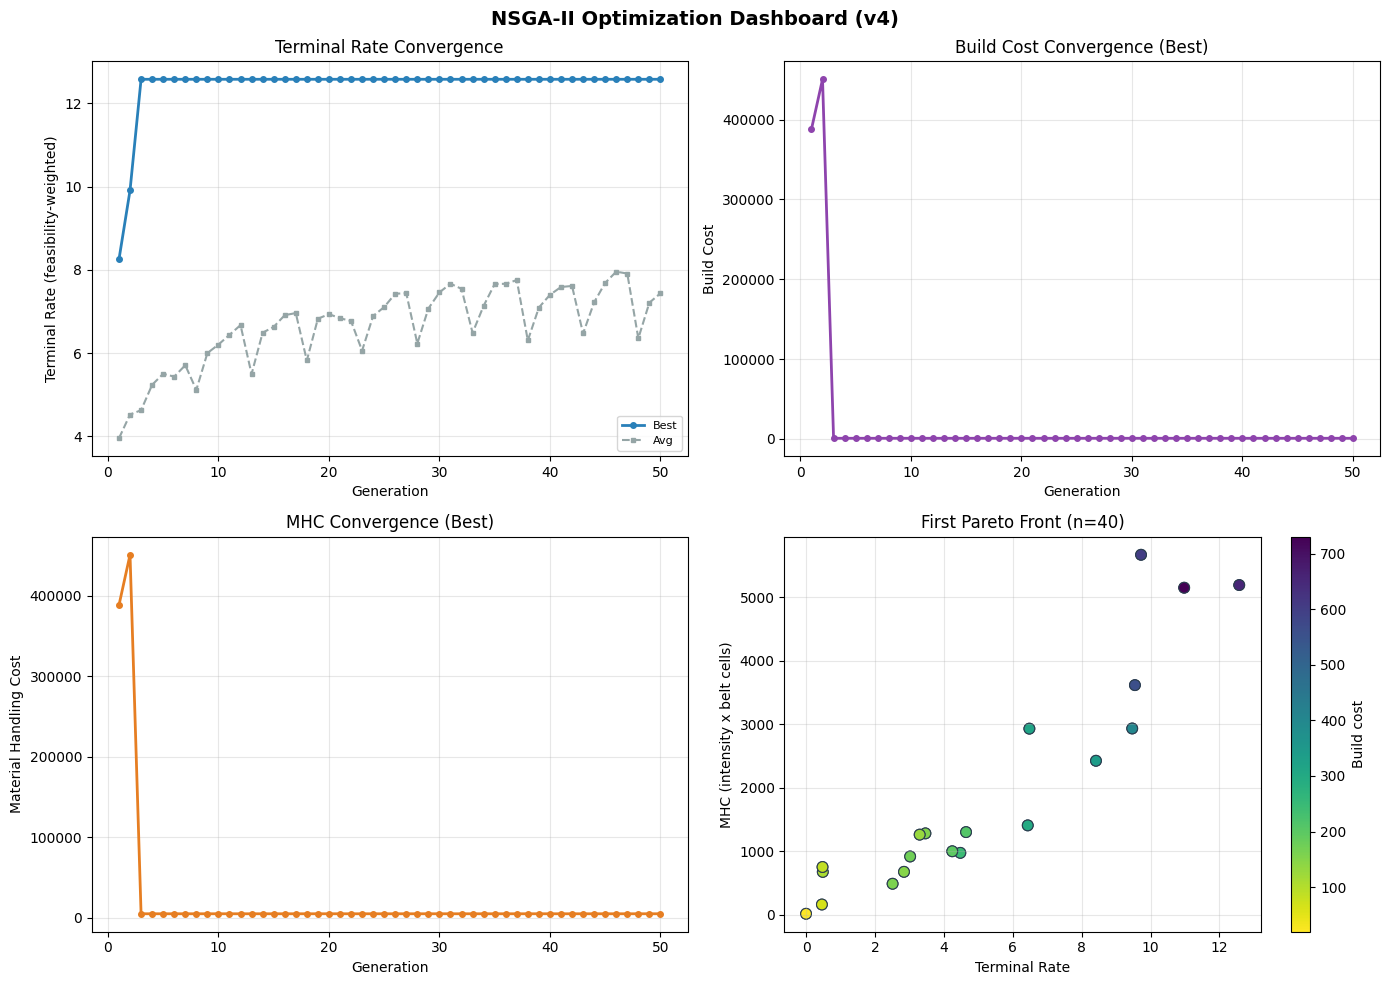

Saved: v4_nsga2_dashboard.png


In [ ]:
# ─── NSGA-II CONVERGENCE & PARETO FRONT VISUALIZATION ───────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('NSGA-II Optimization Dashboard (v4)', fontsize=14, fontweight='bold')

# 1. Terminal-rate convergence (already folds the graded feasibility score in
#    — see evaluate_nsga2 — so this is the closest v4 analogue of the old
#    "Feasibility Convergence" + "Revenue Convergence" panels combined)
ax = axes[0, 0]
ax.plot(conv_history['gen'], conv_history['best_rate'], 'o-',
        color='#2980B9', linewidth=2, markersize=4, label='Best')
ax.plot(conv_history['gen'], conv_history['avg_rate'], 's--',
        color='#95A5A6', linewidth=1.5, markersize=3, label='Avg')
ax.set_xlabel('Generation')
ax.set_ylabel('Terminal Rate (feasibility-weighted)')
ax.set_title('Terminal Rate Convergence')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 2. Build cost convergence
ax = axes[0, 1]
ax.plot(conv_history['gen'], conv_history['best_cost'], 'o-',
        color='#8E44AD', linewidth=2, markersize=4)
ax.set_xlabel('Generation')
ax.set_ylabel('Build Cost')
ax.set_title('Build Cost Convergence (Best)')
ax.grid(alpha=0.3)

# 3. MHC convergence
ax = axes[1, 0]
ax.plot(conv_history['gen'], conv_history['best_mhc'], 'o-',
        color='#E67E22', linewidth=2, markersize=4)
ax.set_xlabel('Generation')
ax.set_ylabel('Material Handling Cost')
ax.set_title('MHC Convergence (Best)')
ax.grid(alpha=0.3)

# 4. True first Pareto front (Terminal Rate vs MHC, coloured by build cost).
#    This used to colour by ind._flp_cache['main_feas'], which is set inside
#    evaluate_nsga2 -- i.e. inside a joblib WORKER process. Only the fitness
#    tuple is returned to the parent, so the attribute never existed here and
#    getattr(..., {}) silently painted every point 0.0. Build cost is objective
#    0, so it is available on the fitness tuple itself and is always correct.
ax = axes[1, 1]
rate_vals = [ind.fitness.values[1] for ind in pareto_front]
mhc_vals  = [ind.fitness.values[2] for ind in pareto_front]
cost_vals = [ind.fitness.values[0] for ind in pareto_front]
sc = ax.scatter(rate_vals, mhc_vals, c=cost_vals, cmap='viridis_r',
                s=60, edgecolors='#2C3E50', linewidth=0.8)
plt.colorbar(sc, ax=ax, label='Build cost')
ax.set_xlabel('Terminal Rate')
ax.set_ylabel('MHC (intensity x belt cells)')
ax.set_title(f'First Pareto Front (n={len(pareto_front)})')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('v4_nsga2_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: v4_nsga2_dashboard.png")

## Shot 3 and 4 — A layout, and the three states

Pre-disruption, un-recovered, and post-recovery for each of five layouts. The crater and the two radii are drawn as concentric rings.

  Best Partial 1: Best Partial 1 — worst of 5 scenarios  |  crater 3x3 at (44,60)  r1=5 r2=12  |  destroyed=1  movable=7  relocated=0  |  regret=0.0000 (mean 0.0000)  recovered 100% of what the bomb cost


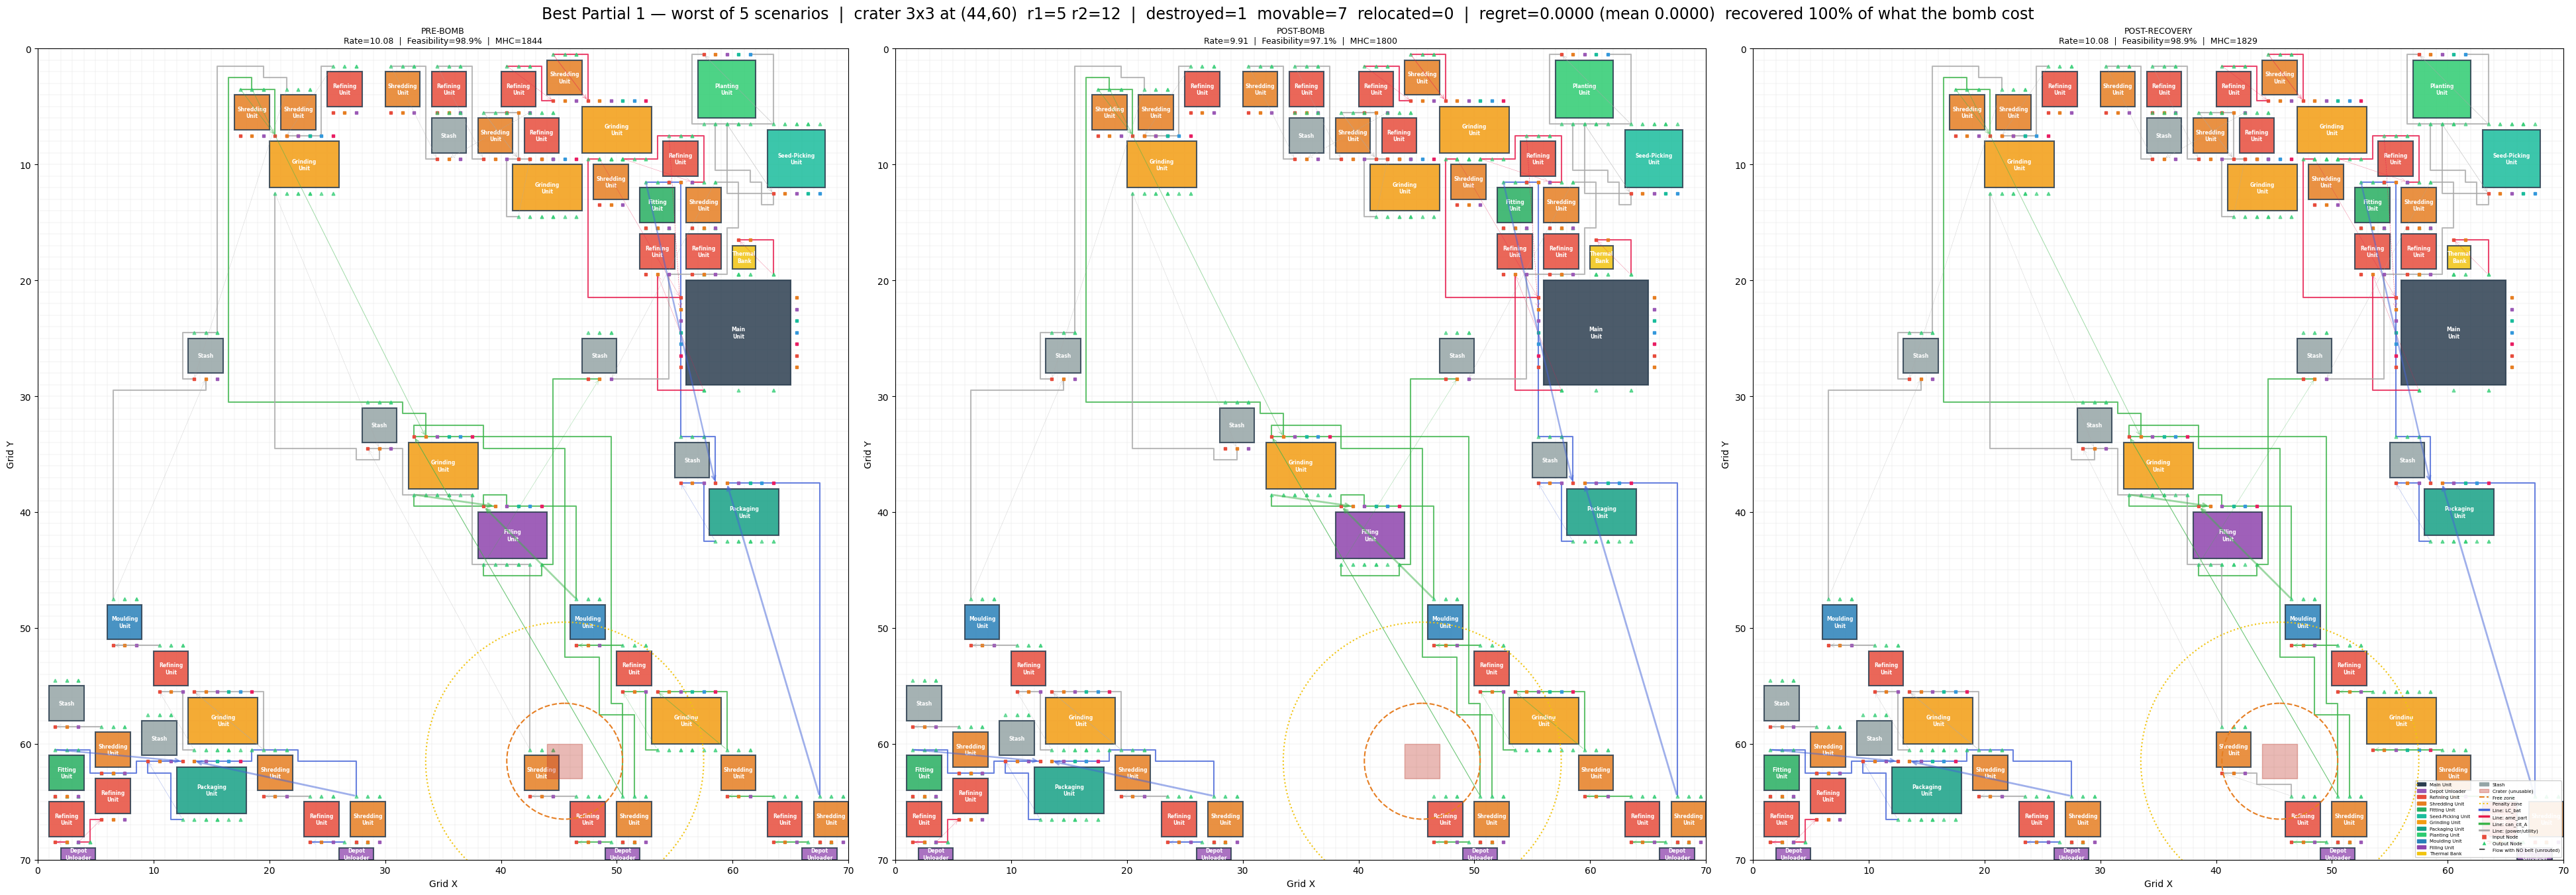

Saved to v4_layout_best_partial_1_sequence.png
  Best Partial 2: Best Partial 2 — worst of 5 scenarios  |  crater 3x3 at (58,54)  r1=5 r2=12  |  destroyed=1  movable=9  relocated=0  |  regret=0.0000 (mean 0.0000)  recovered 100% of what the bomb cost


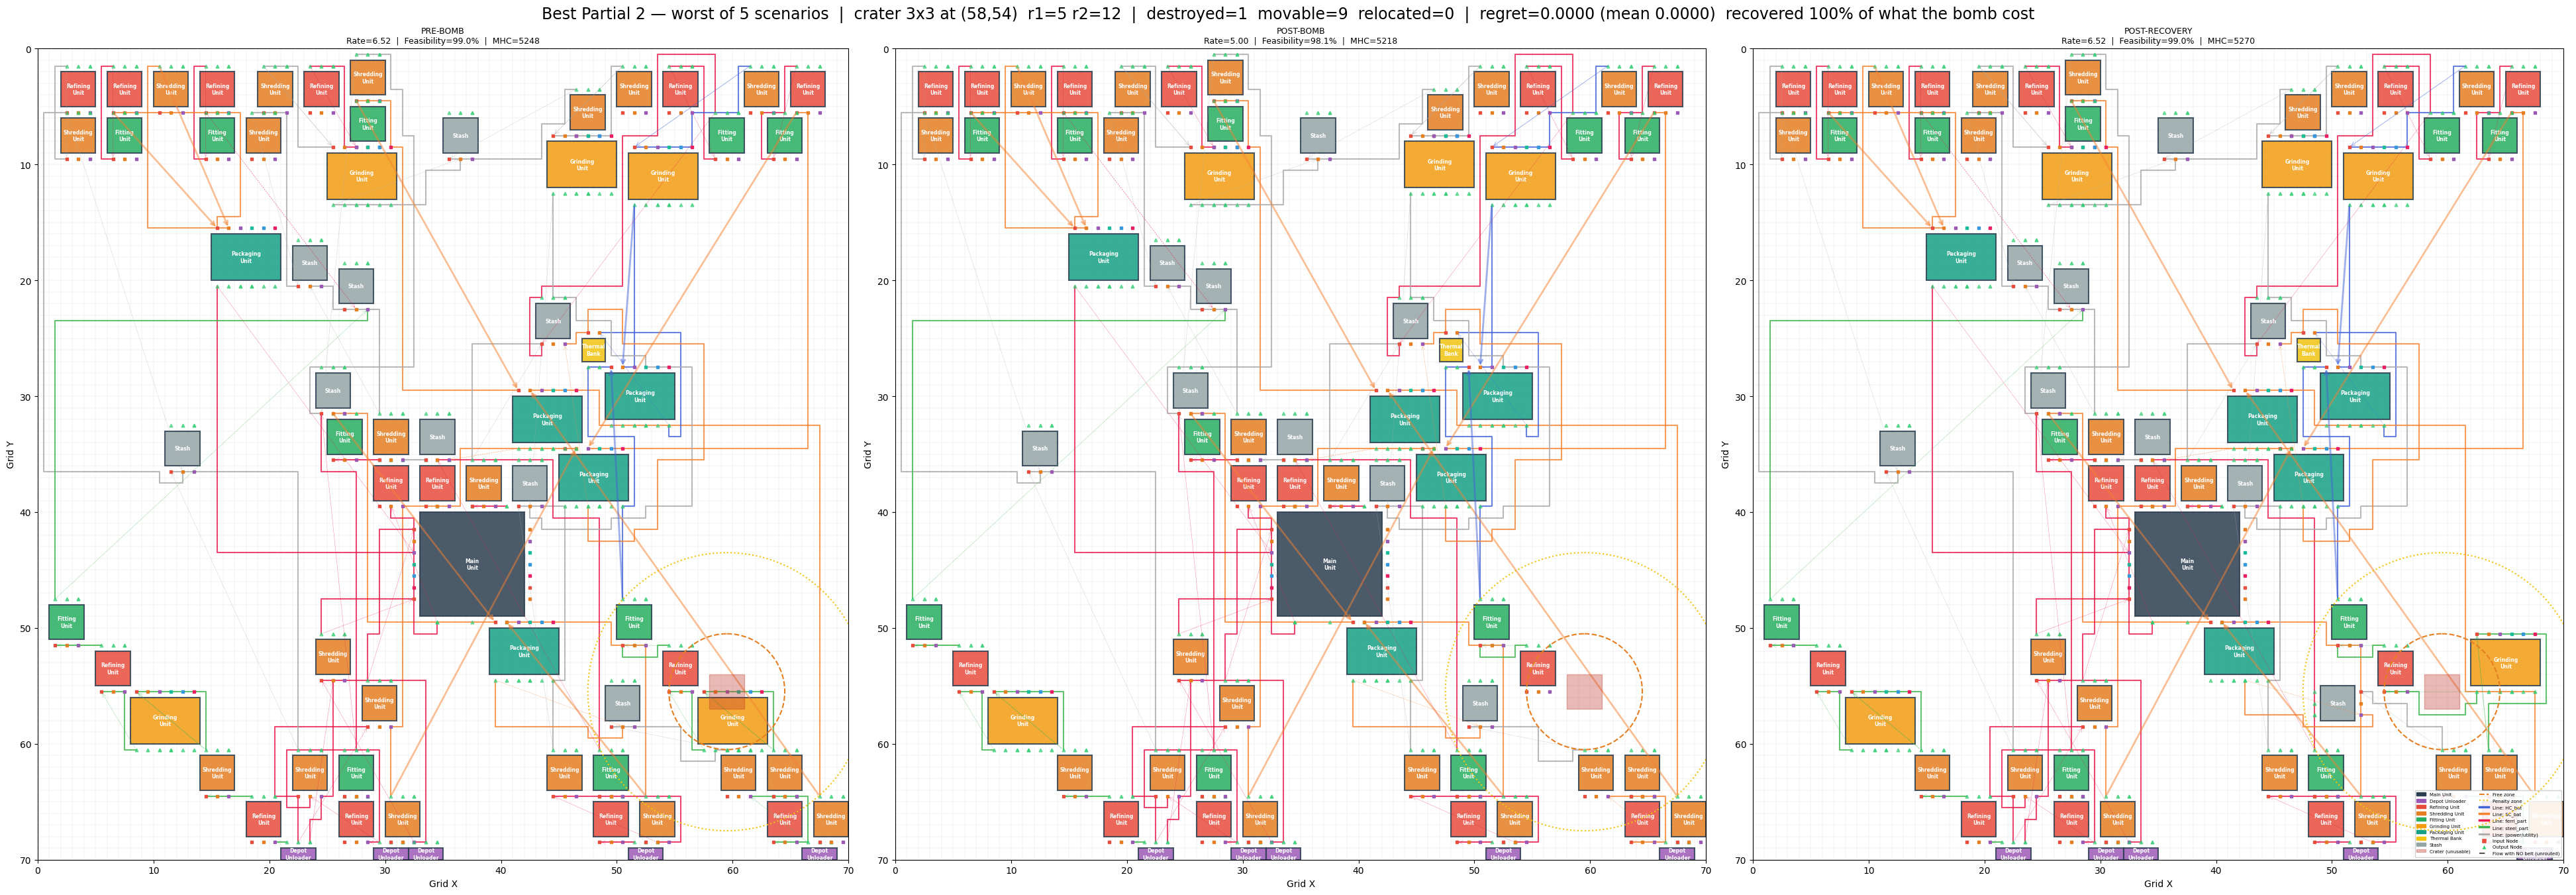

Saved to v4_layout_best_partial_2_sequence.png
  Best Partial 3: Best Partial 3 — worst of 5 scenarios  |  crater 3x3 at (39,35)  r1=5 r2=12  |  destroyed=1  movable=5  relocated=0  |  regret=0.0250 (mean 0.0096)  recovered 79% of what the bomb cost


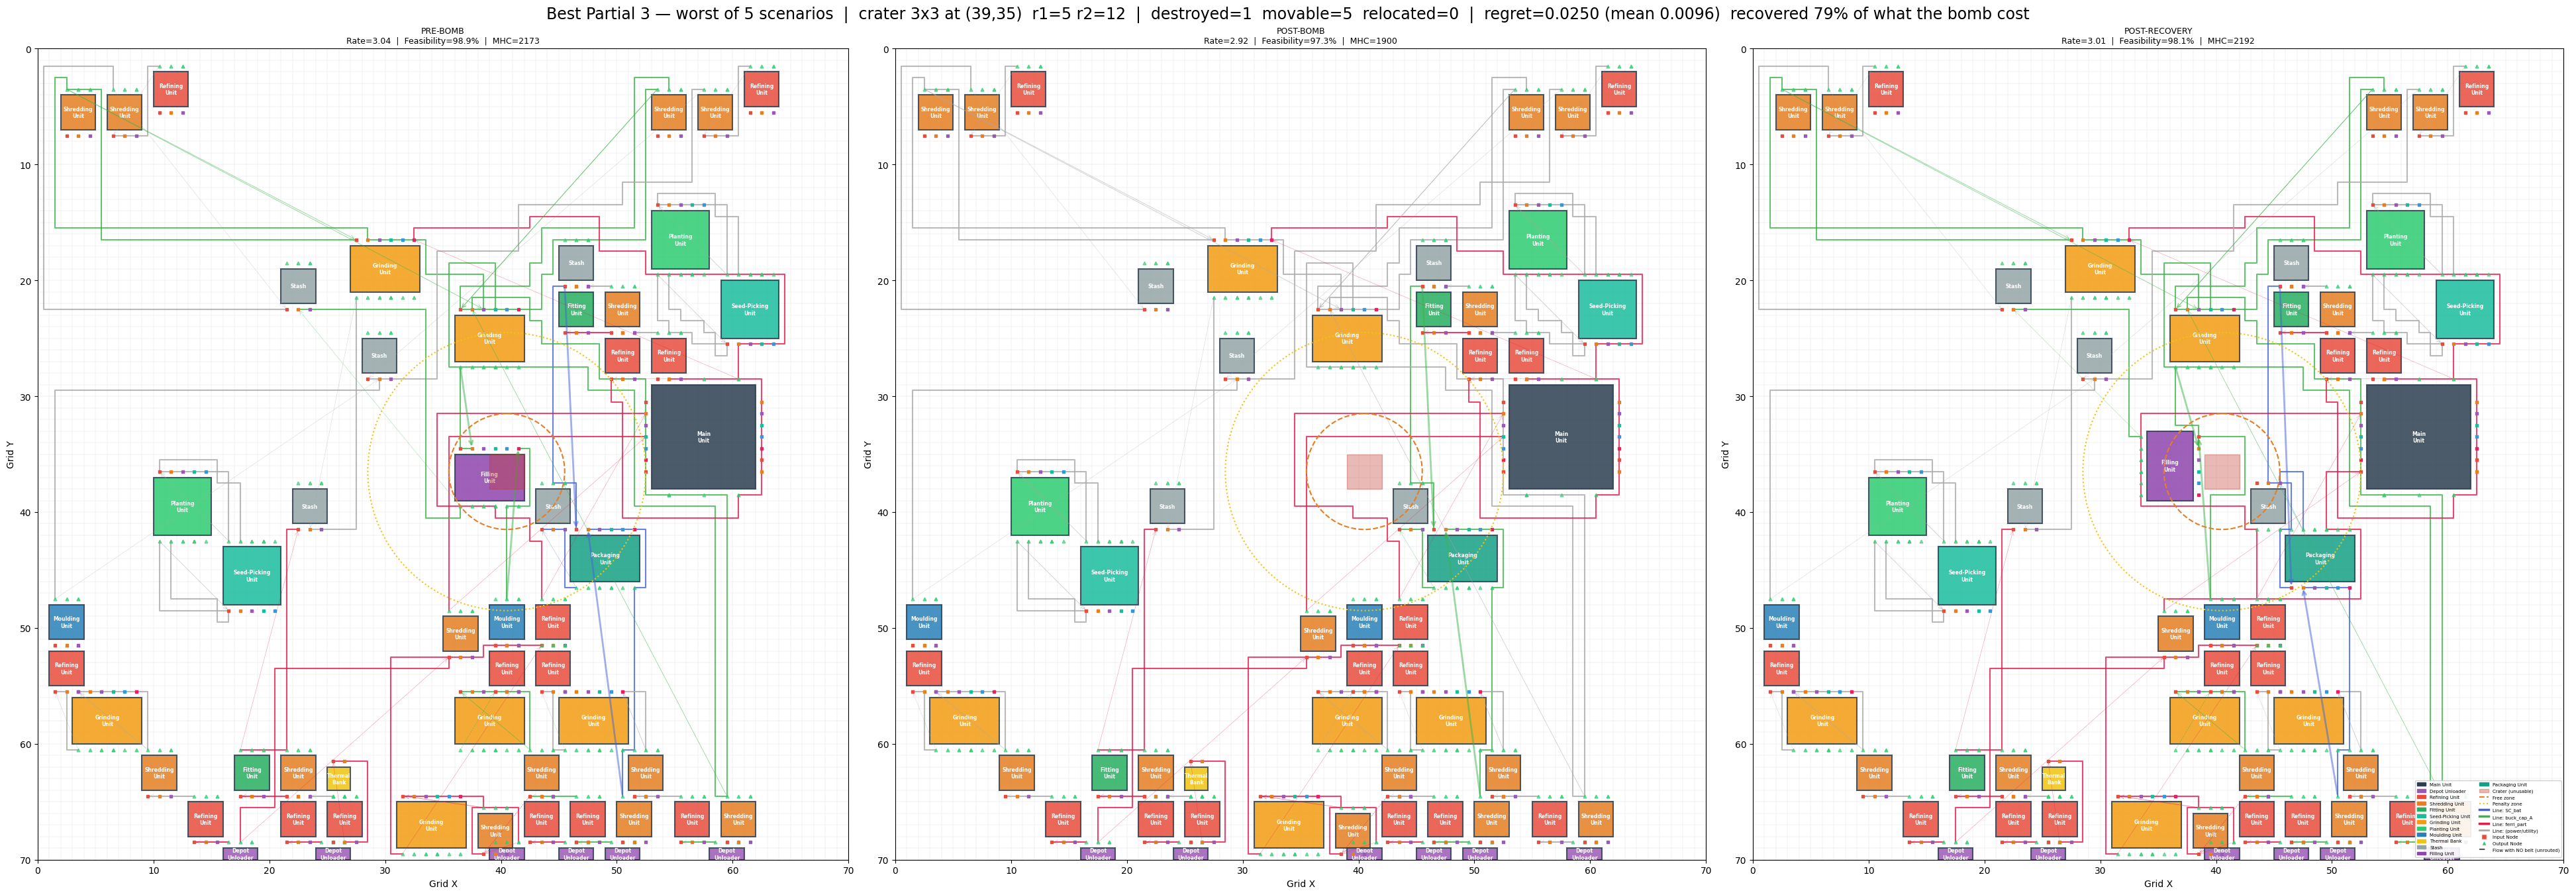

Saved to v4_layout_best_partial_3_sequence.png
  Best Partial 4: Best Partial 4 — worst of 5 scenarios  |  crater 3x3 at (24,22)  r1=5 r2=12  |  destroyed=1  movable=2  relocated=0  |  regret=0.0000 (mean 0.0000)  recovered 100% of what the bomb cost


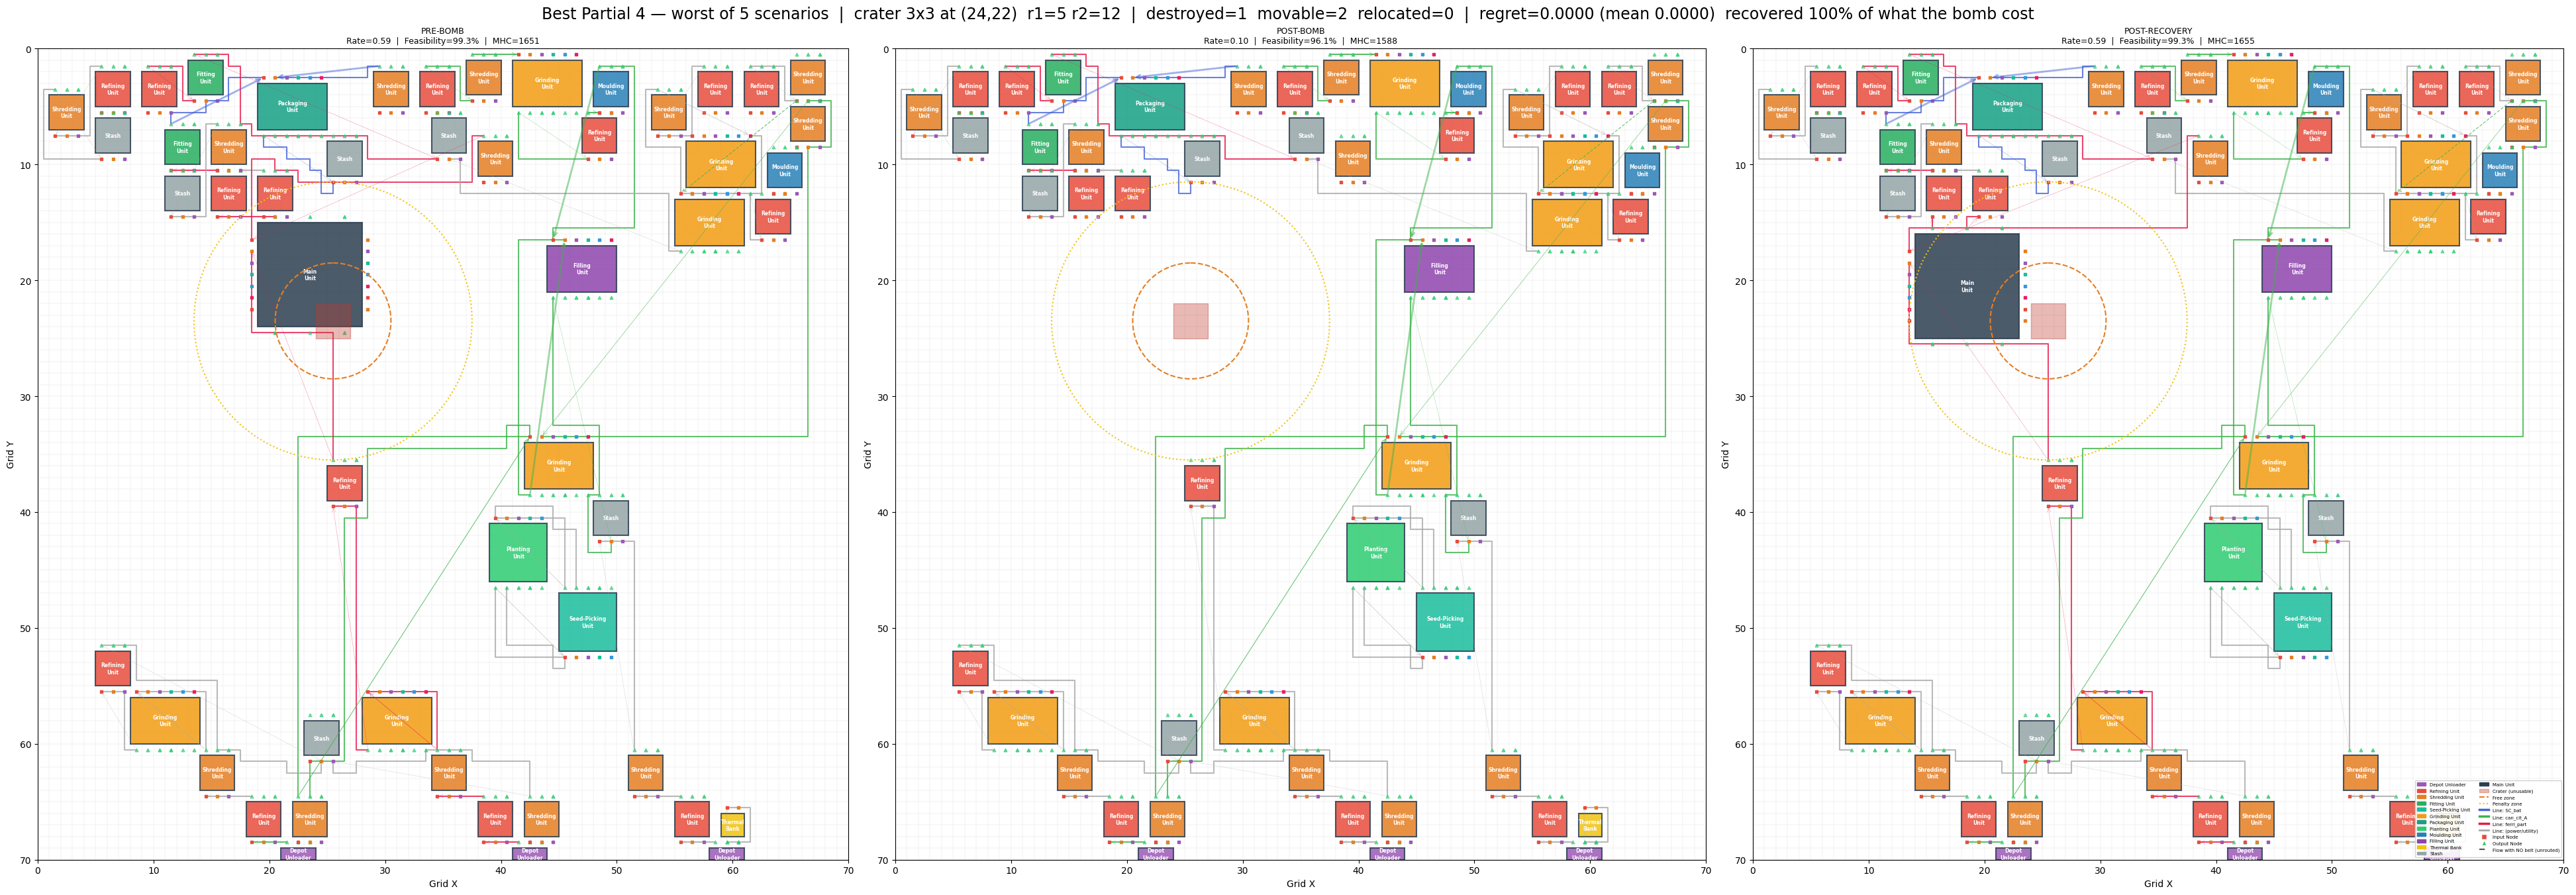

Saved to v4_layout_best_partial_4_sequence.png
  Best Partial 5: Best Partial 5 — worst of 5 scenarios  |  crater 3x3 at (21,3)  r1=5 r2=12  |  destroyed=3  movable=9  relocated=2  |  regret=0.0000 (mean 0.0000)  recovered 112% of what the bomb cost


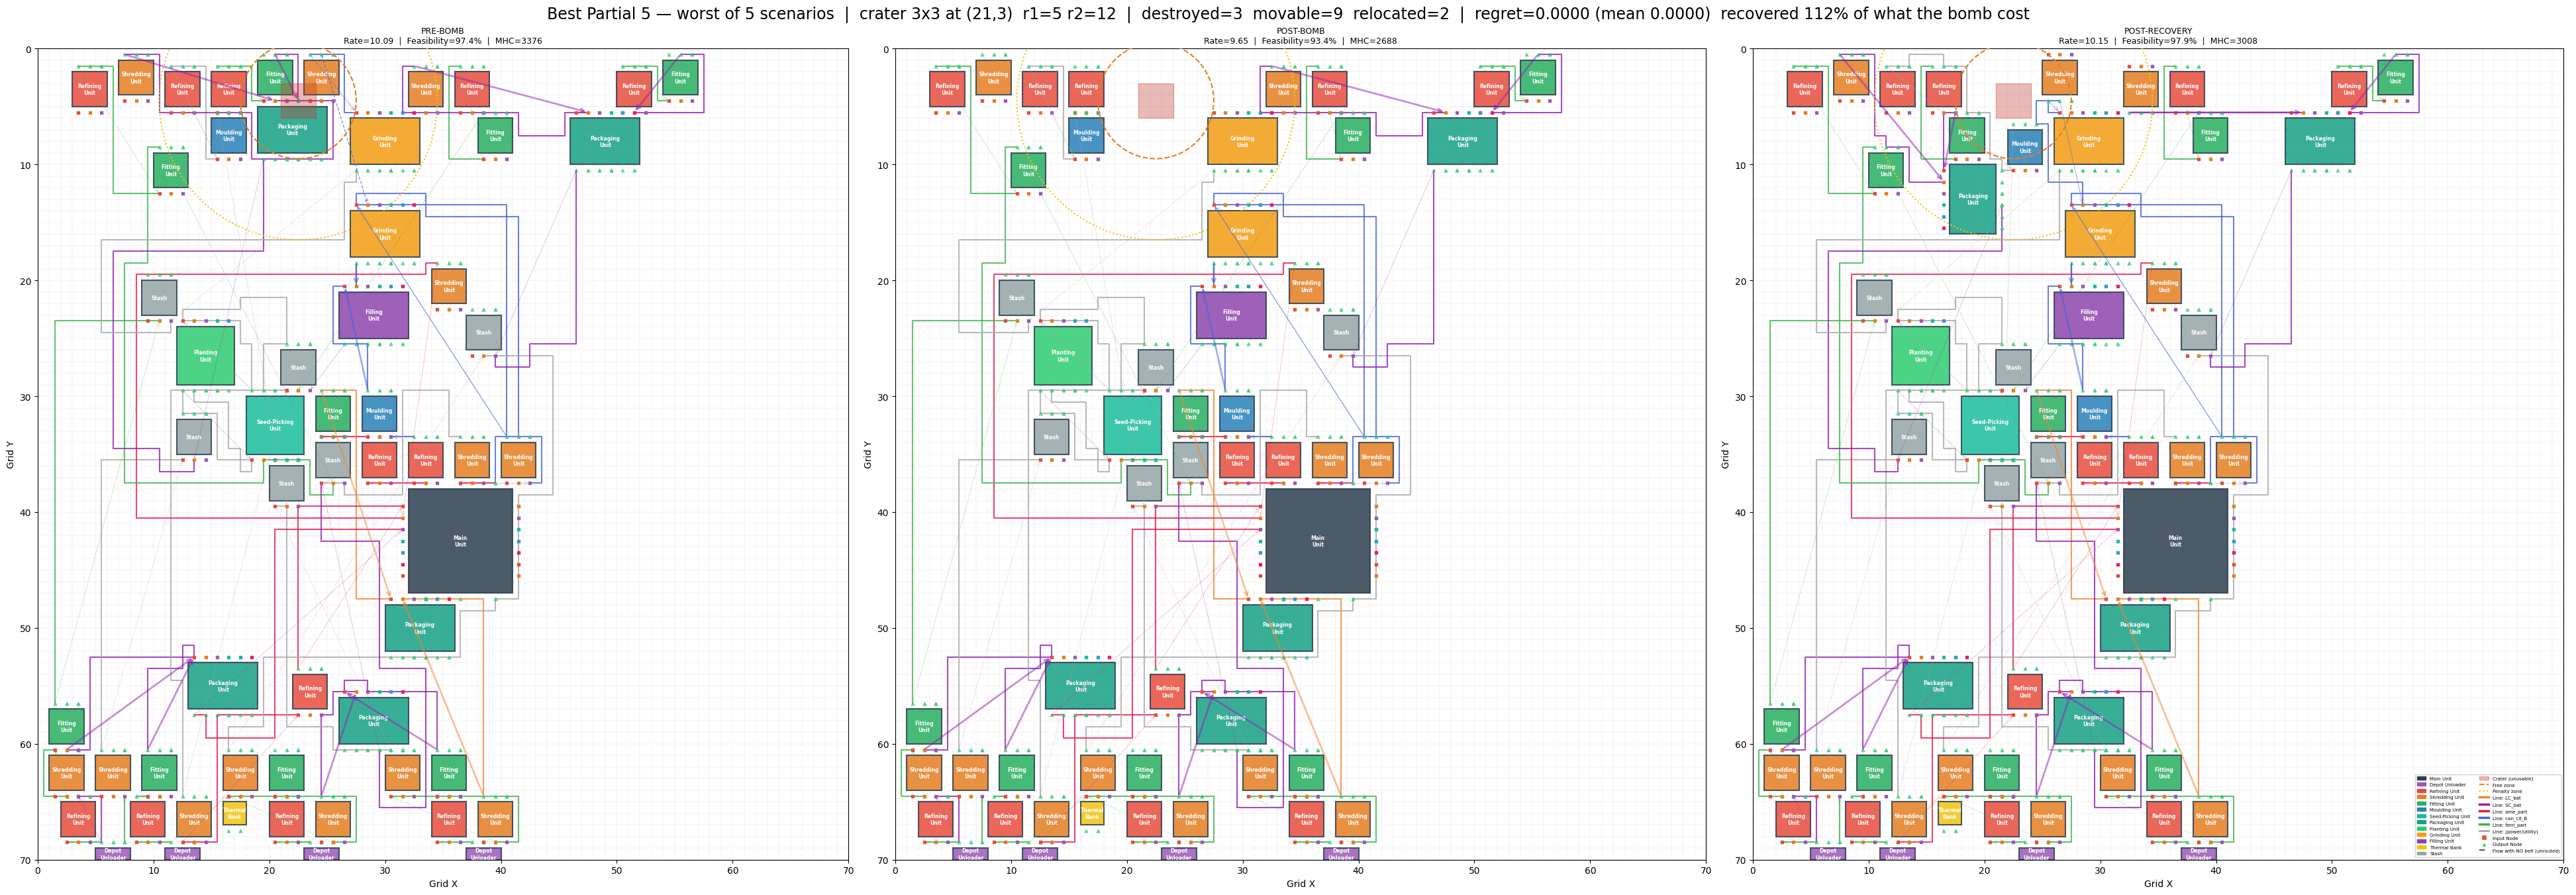

Saved to v4_layout_best_partial_5_sequence.png


In [ ]:
# ─── VISUALIZATION ──────────────────────────────────────────────────────────────
# The crater is per-layout, not per-config: Phase 4 samples ZPF_SCENARIOS
# positions per layout and carries the WORST one into the cache. Drawing
# CFG.ZPF_X/ZPF_Y here put the rectangle and rings somewhere the bomb never
# landed, which is why recovered layouts appeared to have machines and belts
# sitting inside the crater.
_ZPF_DEFAULT = ZPF(CFG.ZPF_X, CFG.ZPF_Y, CFG.ZPF_W, CFG.ZPF_H, CFG.ZPF_R1, CFG.ZPF_R2)

for idx, (ind, result, terminal_rate, total_genes, chromo, main_feas) in enumerate(top_layouts):
    cache = ind._flp_cache
    zpf_result, zpf_feas = cache["zpf"], cache["zpf_feas"]
    zpf_zone_for_plot = cache.get("zone") or _ZPF_DEFAULT

    label = f"Top {idx+1}" if result["feasible"] else f"Best Partial {idx+1}"
    _w = cache.get("worst_run") or {}
    _frac = _w.get("fraction", float("nan"))
    _frac_s = "n/a" if _frac != _frac else f"{_frac:.0%}"
    _scenario_note = (
        f"{label} — worst of {len(cache.get('runs') or [1])} scenarios  |  "
        f"crater {zpf_zone_for_plot.w}x{zpf_zone_for_plot.h} at "
        f"({zpf_zone_for_plot.x},{zpf_zone_for_plot.y})  "
        f"r1={zpf_zone_for_plot.r1:g} r2={zpf_zone_for_plot.r2:g}  |  "
        f"destroyed={_w.get('destroyed', '?')}  "
        f"movable={_w.get('movable', '?')}  "
        f"relocated={_w.get('disturbed', '?')}  |  "
        f"regret={cache.get('worst_regret', 0.0):.4f} "
        f"(mean {cache.get('mean_regret', 0.0):.4f})  "
        f"recovered {_frac_s} of what the bomb cost"
    )
    print(f"  {label}: {_scenario_note}")
    fname_base = f"v4_layout_{label.lower().replace(' ', '_')}"

    # --- Multi-panel: Pre-Bomb | Post-Bomb (un-recovered) | Post-Recovery ---
    # The middle panel is the SAME object Phase 4 scored, not a fresh
    # reconstruction. It used to be rebuilt here with derive_flow_matrix() from
    # scratch, which re-runs a greedy order-dependent match on the surviving
    # machines: the panel showed a different supply plan, so the drop it
    # depicted was partly a re-match rather than the damage. See P8 and
    # post_bomb_state().
    try:
        post_bomb_result = cache.get("post_bomb")
        if post_bomb_result is None:
            post_bomb_result = post_bomb_state(result, zpf_zone_for_plot)
        post_bomb_feas = cache.get("pb_feas")
        if post_bomb_feas is None:
            post_bomb_feas = _feasibility_ratio(post_bomb_result, total_genes)
        post_bomb_rate = cache.get("pb_rate", post_bomb_result["revenue"] * post_bomb_feas)

        plot_zpf_sequence(
            pre_result=result,
            post_result=post_bomb_result,
            rec_result=zpf_result,
            zpf_zone=zpf_zone_for_plot,
            pre_feas=main_feas,
            post_feas=post_bomb_feas,
            rec_feas=zpf_feas,
            pre_rate=terminal_rate,
            post_rate=post_bomb_rate,
            rec_rate=zpf_result["revenue"] * zpf_feas,
            scenario_note=_scenario_note,
            save_path=f"{fname_base}_sequence.png",
        )
    except Exception:
        print(f"\n[MATPLOTLIB EXCEPTION IN plot_zpf_sequence for {label}]:")
        traceback.print_exc()


## Shot 4b — The three-state scenario report, and Shot 5 — the assertions

**Find these by searching:** `REGRET over` for the per-layout summary, `Crater integrity` for the assertion, `PRODUCTION` for the ledger, `effort: method` for the search-effort log.

In [ ]:
# ─── PHASE 4: ZPF DISASTER SIMULATION ───────────────────────────────────────────
print("=" * 70)
print("PHASE 4: ZPF Disaster Simulation — Bombing top layouts")
print("=" * 70)

# Dedupe again: Phase 3 can leave duplicates if two candidates converged.
_seen_layout, top_layouts = set(), []
for _entry in refined:
    if len(top_layouts) >= CFG.PHASE4_TOP_N:
        break
    _k = tuple((g.machine_id, g.recipe_idx) for g in _entry[4].genes)
    if _k in _seen_layout:
        continue
    _seen_layout.add(_k)
    top_layouts.append(_entry)
print(f"Bombing {len(top_layouts)} DISTINCT layout(s) of {len(refined)} polished candidates.")
print("Every scenario reports THREE states, not two:")
print("    pre        the layout before the bomb")
print("    post-bomb  the crater blocked and its machines gone, NOTHING recovered")
print("    post-rec   after the recovery search")
print("  regret = pre - post-rec        conflates how bad the bomb was with how")
print("                                 well the algorithm recovered")
print("  gain   = post-rec - post-bomb  what the recovery actually contributed")
print("  frac   = gain / (pre - post-bomb)   the same, normalised, so it is")
print("                                 comparable across layouts and damage levels")

for idx, (ind, result, terminal_rate, total_genes, chromo, main_feas) in enumerate(top_layouts):
    feas_tag = "FEASIBLE" if result["feasible"] else "PARTIAL"
    # One scenario set per LAYOUT, seeded from the layout itself so every
    # recovery algorithm faces exactly the same craters.
    _layout_seed = _chromosome_repair_seed(chromo)
    scenarios = make_bomb_scenarios(result["placed"], seed=_layout_seed)

    print(f"\n  Layout #{idx+1} [{feas_tag}]  pre-bomb Rate={terminal_rate:.4f}, "
          f"Feasibility={main_feas:.1%}   [{_feas_str(result, total_genes)}]")
    # What that rate is actually made of, before anything is bombed.
    production_report(result["placed"], result["routed"],
                      title=f"Layout #{idx+1} PRE-BOMB", feasibility=main_feas,
                      indent="    ")
    check_raw_dependencies(result["placed"], result["routed"], indent="    ")
    print(f"    {len(scenarios)} scenario(s), rejection-sampled to guarantee damage")

    # The comparable baseline: the SAME layout, undamaged, re-routed on a fresh
    # grid exactly as everything downstream of the bomb is. The pre-bomb belts
    # were laid incrementally by blf_decode -> ALNS -> Tabu -> connect_or_remove
    # -> repair_feasibility; the recovery re-lays all of them at once. Comparing
    # a post-bomb rate to the pre-bomb rate mixes the crater with that
    # difference, and the difference is not small.
    ref = post_bomb_state(result, None)
    ref_feas = _feasibility_ratio(ref, total_genes)
    ref_rate = ref["revenue"] * ref_feas
    print(f"    clean re-route reference (no crater): Rate={ref_rate:.4f} "
          f"feas={ref_feas:.1%}   [{_feas_str(ref, total_genes)}]"
          f"   re-route effect {ref_rate - terminal_rate:+.4f}")
    # Belt reuse. With no crater every belt should be re-laid unchanged, so a
    # reference that is NOT ~100% reused means something other than the blast is
    # invalidating belts -- check CFG.ZPF_PRESERVE_BELTS and the position/
    # rotation match in _reuse_belts. Any residual re-route effect here is flows
    # that were UNROUTED pre-bomb being re-attempted and now succeeding, which
    # changes the chain graph; that is correct behaviour, not an A* artefact.
    _ref_reused, _ref_flows = ref.get("belts_reused", 0), len(ref.get("flows") or ())
    print(f"      belts preserved: {_ref_reused}/{_ref_flows}"
          f"{' (' + format(_ref_reused / _ref_flows, '.0%') + ')' if _ref_flows else ''}")

    runs = []
    for s_i, zone in enumerate(scenarios):
        destroyed, movable = scenario_damage(result["placed"], zone)

        # R1's missing baseline: the damaged layout with NO recovery applied,
        # built on the same preserved flow plan the recovery uses, so all three
        # states are the same graph and the differences mean something.
        pb = post_bomb_state(result, zone)
        pb_feas = _feasibility_ratio(pb, total_genes)
        pb_rate = pb["revenue"] * pb_feas

        rng = random.Random(_layout_seed ^ (s_i * 0x9E3779B1))
        zpf_result, _ = zpf_recovery(chromo, zone, iterations=CFG.ZPF_ITERATIONS,
                                     rng=rng, base=result)
        zfeas  = _feasibility_ratio(zpf_result, total_genes)
        zrate  = zpf_result["revenue"] * zfeas
        regret, gain, frac = recovery_metrics(terminal_rate, pb_rate, zrate,
                                              ref_rate=ref_rate)
        _rlog = zpf_result.get("recovery_log") or {}
        runs.append(dict(scenario=s_i, zone=zone, result=zpf_result, feas=zfeas,
                         reclog=_rlog, post_bomb=pb, pb_feas=pb_feas, pb_rate=pb_rate,
                         ref_rate=ref_rate,
                         rate=zrate, regret=regret, gain=gain, fraction=frac,
                         destroyed=destroyed, movable=movable,
                         disturbed=zpf_result.get("machines_disturbed", 0),
                         unplaced=len(zpf_result.get("unplaced_ids", []))))
        # The crater must be empty in BOTH downstream states. See
        # crater_violations for why this is asserted rather than assumed.
        for _state_name, _state in (("post-bomb", pb), ("post-recovery", zpf_result)):
            _bad_m, _bad_b = crater_violations(_state, zone)
            assert not _bad_m and not _bad_b, (
                f"crater violated in {_state_name} state, layout #{idx+1} "
                f"scenario {s_i+1} at ({zone.x},{zone.y}): "
                f"machines={_bad_m} belts={_bad_b}")

        _frac_s = "  n/a" if frac != frac else f"{frac:5.1%}"
        print(f"      #{s_i+1:>2} crater({zone.x:>2},{zone.y:>2})  destroyed={destroyed} "
              f"movable={movable:>3}  rate {terminal_rate:7.4f} -> {pb_rate:7.4f} -> {zrate:7.4f}"
              f"  regret={regret:7.4f}  gain={gain:+7.4f}  frac={_frac_s}"
              f"  disturbed={runs[-1]['disturbed']}")

    regrets = [r["regret"] for r in runs]
    gains   = [r["gain"] for r in runs]
    fracs   = [r["fraction"] for r in runs if r["fraction"] == r["fraction"]]
    mean_r  = sum(regrets) / len(regrets)
    mean_g  = sum(gains) / len(gains)
    mean_f  = (sum(fracs) / len(fracs)) if fracs else float("nan")
    worst   = max(runs, key=lambda r: r["regret"])
    median  = sorted(regrets)[len(regrets) // 2]
    zero    = sum(1 for r in regrets if r <= 1e-9)
    # A bomb that IMPROVES the layout is a modelling defect, not a result. It
    # used to be invisible because regret clamps at zero; counted explicitly
    # now, since it is the single most informative diagnostic in this phase.
    helped  = sum(1 for r in runs if r["pb_rate"] > ref_rate + 1e-9)
    print(f"    REGRET over {len(runs)} scenario(s): mean={mean_r:.4f}  median={median:.4f}  "
          f"worst={worst['regret']:.4f} (crater {worst['zone'].x},{worst['zone'].y})  "
          f"zero-regret={zero}/{len(runs)}")
    _mf = "n/a" if mean_f != mean_f else f"{mean_f:.1%}"
    print(f"    RECOVERY: mean gain={mean_g:+.4f}  mean recovered fraction={_mf}"
          f"   (scenarios where the BOMB IMPROVED the layout: {helped}/{len(runs)})")
    # The same ledger for the state Phase 5/6 carry forward, so the drop in
    # rate can be attributed to a material rather than left as a delta.
    production_report(worst["result"]["placed"], worst["result"]["routed"],
                      title=f"Layout #{idx+1} POST-RECOVERY "
                            f"(worst crater {worst['zone'].x},{worst['zone'].y})",
                      feasibility=worst["feas"], indent="    ")
    print(f"    damage: mean destroyed="
          f"{sum(r['destroyed'] for r in runs)/len(runs):.2f}, "
          f"mean movable={sum(r['movable'] for r in runs)/len(runs):.1f}")

    # Recovery EFFORT, averaged over the scenario set. Final quality alone does
    # not separate two methods that reach the same layout at different cost.
    _logs = [r["reclog"] for r in runs if r.get("reclog")]
    if _logs:
        _ev   = sum(l.get("evaluations", 0)    for l in _logs) / len(_logs)
        _etb  = sum(l.get("evals_to_best", 0)  for l in _logs) / len(_logs)
        _dist = [l.get("distinct_costs") for l in _logs if l.get("distinct_costs")]
        _line = (f"    effort: method={_logs[0].get('method','?')}  "
                 f"mean evaluations={_ev:.0f}  mean evals-to-best={_etb:.0f}  "
                 f"({(1 - _etb / max(1e-9, _ev)):.0%} of the budget bought nothing)")
        if _dist:
            # How much of the budget saw a layout it had never seen before. A
            # permutation neighbourhood over machines that all go straight back
            # to their original coordinates re-evaluates the same layout almost
            # every iteration; this is the number that exposes it.
            _line += (f"\n            distinct costs={sum(_dist)/len(_dist):.1f}"
                      f" of {_ev:.0f} evaluations")
        _reused = [r["result"].get("belts_reused") for r in runs
                   if r["result"].get("belts_reused") is not None]
        _pbre = [r["post_bomb"].get("belts_reused") for r in runs
                 if r.get("post_bomb") and r["post_bomb"].get("belts_reused") is not None]
        if _reused:
            _line += (f"\n            belts preserved: {sum(_reused)/len(_reused):.0f} "
                      f"in the best recovery, {sum(_pbre)/max(1,len(_pbre)):.0f} "
                      f"in the un-recovered state (CFG.ZPF_PRESERVE_BELTS)")
        if "acceptance_rate" in _logs[0]:
            _ar = sum(l["acceptance_rate"] for l in _logs) / len(_logs)
            _ir = sum(l["improvement_rate"] for l in _logs) / len(_logs)
            _line += f"\n            acceptance={_ar:.1%}  improvement={_ir:.1%}"
        print(_line)

    # The WORST case is carried forward for Phase 5/6 -- a resilience claim
    # should be made against the hardest scenario, not a lucky one.
    zpf_result, zpf_feas, regret = worst["result"], worst["feas"], worst["regret"]
    ind._flp_cache = dict(result=result, zpf=zpf_result, terminal_rate=terminal_rate,
                           zone=worst["zone"],   # the crater that PRODUCED zpf_result
                           worst_run=worst,
                           post_bomb=worst["post_bomb"], pb_feas=worst["pb_feas"],
                           pb_rate=worst["pb_rate"], ref_rate=ref_rate,
                           ref_feas=ref_feas,
                           main_feas=main_feas, zpf_feas=zpf_feas, total_genes=total_genes,
                           runs=runs, mean_regret=mean_r, worst_regret=worst["regret"],
                           median_regret=median, mean_gain=mean_g, mean_fraction=mean_f,
                           bomb_helped=helped)

# ── Cross-layout summary ─────────────────────────────────────────────────────
print("\n" + "=" * 96)
print("PHASE 4 SUMMARY — regret and recovery distribution per layout")
print("=" * 96)
print(f"{'Layout':>8}{'scen':>6}{'pre-rate':>10}{'post-bomb':>11}{'mean reg':>10}"
      f"{'worst reg':>11}{'mean gain':>11}{'mean frac':>11}{'zero':>7}{'destroyed':>11}")
for idx, (ind, result, terminal_rate, *_rest) in enumerate(top_layouts):
    ch = getattr(ind, "_flp_cache", {})
    rs = ch.get("runs") or []
    if not rs:
        continue
    _pb = sum(r["pb_rate"] for r in rs) / len(rs)
    _mf = ch.get("mean_fraction", float("nan"))
    _mfs = "n/a" if _mf != _mf else f"{_mf:>10.1%}"
    print(f"{'#'+str(idx+1):>8}{len(rs):>6}{terminal_rate:>10.4f}{_pb:>11.4f}"
          f"{ch['mean_regret']:>10.4f}{ch['worst_regret']:>11.4f}"
          f"{ch['mean_gain']:>+11.4f}{_mfs:>11}"
          f"{sum(1 for r in rs if r['regret'] <= 1e-9):>4}/{len(rs):<2}"
          f"{sum(r['destroyed'] for r in rs)/len(rs):>11.2f}")
_helped_total = sum((getattr(i, '_flp_cache', {}) or {}).get('bomb_helped', 0)
                    for i, *_ in top_layouts)
if _helped_total:
    print(f"\n  [!] {_helped_total} scenario(s) where the UN-RECOVERED post-bomb layout scored")
    print( "      HIGHER than the CLEAN RE-ROUTE REFERENCE. That is a modelling defect --")
    print( "      destroying machines must not improve the factory. Check the sustain gate")
    print( "      (CFG.SUSTAIN_NORMALISE), the routing denominator (_zpf_flow_demand) and")
    print( "      the revenue attribution (CFG.REVENUE_AT_SINK_ONLY).")
print("  Phase 5/6 use the WORST scenario for each layout.")
_n_checked = sum(len((getattr(i, '_flp_cache', {}) or {}).get('runs') or ())
                 for i, *_ in top_layouts)
print(f"  Crater integrity: {2 * _n_checked} state(s) checked, 0 violations "
      f"(asserted per scenario -- see crater_violations).")


PHASE 4: ZPF Disaster Simulation — Bombing top layouts
Bombing 5 DISTINCT layout(s) of 20 polished candidates.
Every scenario reports THREE states, not two:
    pre        the layout before the bomb
    post-bomb  the crater blocked and its machines gone, NOTHING recovered
    post-rec   after the recovery search
  regret = pre - post-rec        conflates how bad the bomb was with how
                                 well the algorithm recovered
  gain   = post-rec - post-bomb  what the recovery actually contributed
  frac   = gain / (pre - post-bomb)   the same, normalised, so it is
                                 comparable across layouts and damage levels

  Layout #1 [PARTIAL]  pre-bomb Rate=10.0828, Feasibility=98.9%   [place 1.00 route 0.97 power 1.00 sust 1.00]
    PRODUCTION — Layout #1 PRE-BOMB   [mode=net]
      material           made/t   used/t    net/t  unit    rev/t   share
      can_cit_A          0.1000   0.0000   0.1000    70   7.0000  68.6%
      LC_bat             0

## Shot 6 — Discrete-event simulation

Four hundred ticks per state. Machine states per tick, cumulative production, and simulated revenue.

PHASE 5: Discrete-time simulation — production timeline & throughput

--- Layout #1 ---
  [SIM] Layout #1 PRE-BOMB: 56 machines, 56 belts, 17 boundary-fed machines
  No equilibrium within 400 ticks
  [SIM] Layout #1 PRE-BOMB: ran=42/56 machines, starved at end=10, sim revenue/tick=4.400, eq_tick=None
  [SIM] Layout #1 PRE-BOMB: live_fraction=93% (needs >= 50% for equilibrium)
  PRODUCTION — Layout #1 PRE-BOMB: analytic vs simulated   [mode=net]
    material           made/t   used/t    net/t  unit    rev/t   share    sim/t   ratio
    can_cit_A          0.1000   0.0000   0.1000    70   7.0000  68.6%   0.0011     1%
    LC_bat             0.2000   0.0000   0.2000    16   3.2000  31.4%   0.0022     1%
    HC_bat             0.0000   0.0100  -0.0100    27   0.0000   0.0%   0.0000       —
    ame_fiber          1.0000   1.0000   0.0000     0   0.0000   0.0%   0.0333     3%
    ame_ore            0.0000   1.0000  -1.0000     0   0.0000   0.0%   0.0000       —
    ame_part           1.0000  

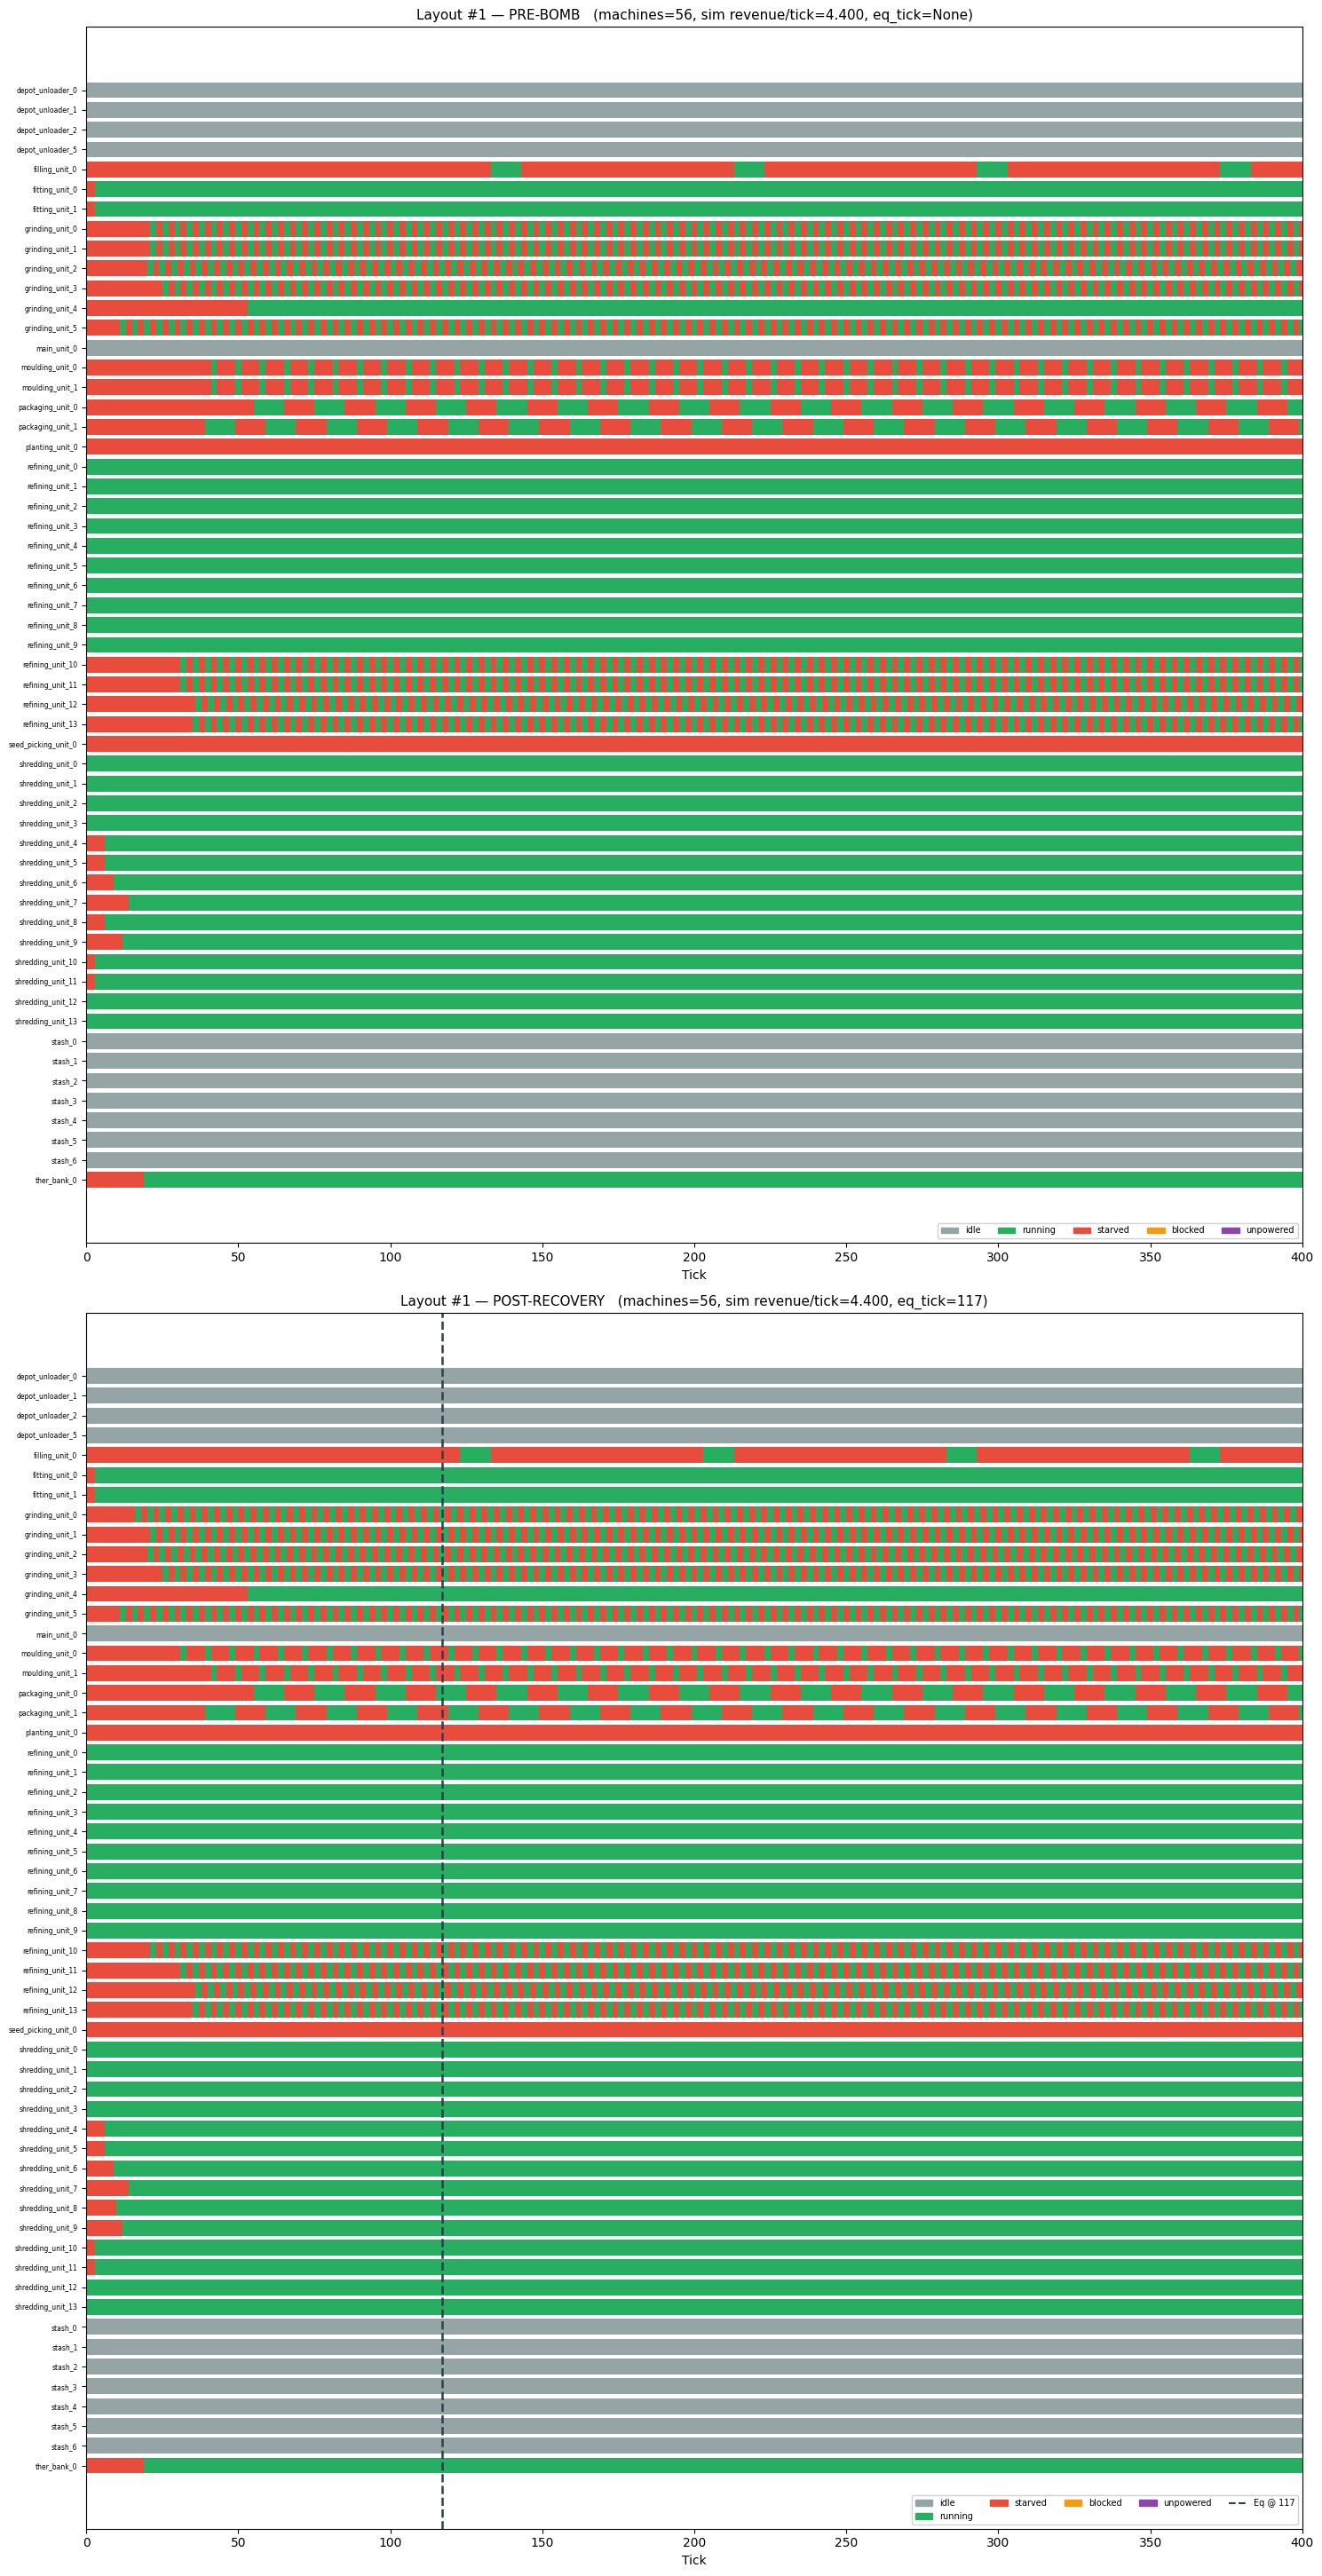

  Saved v4_sim_gantt_layout_1.png


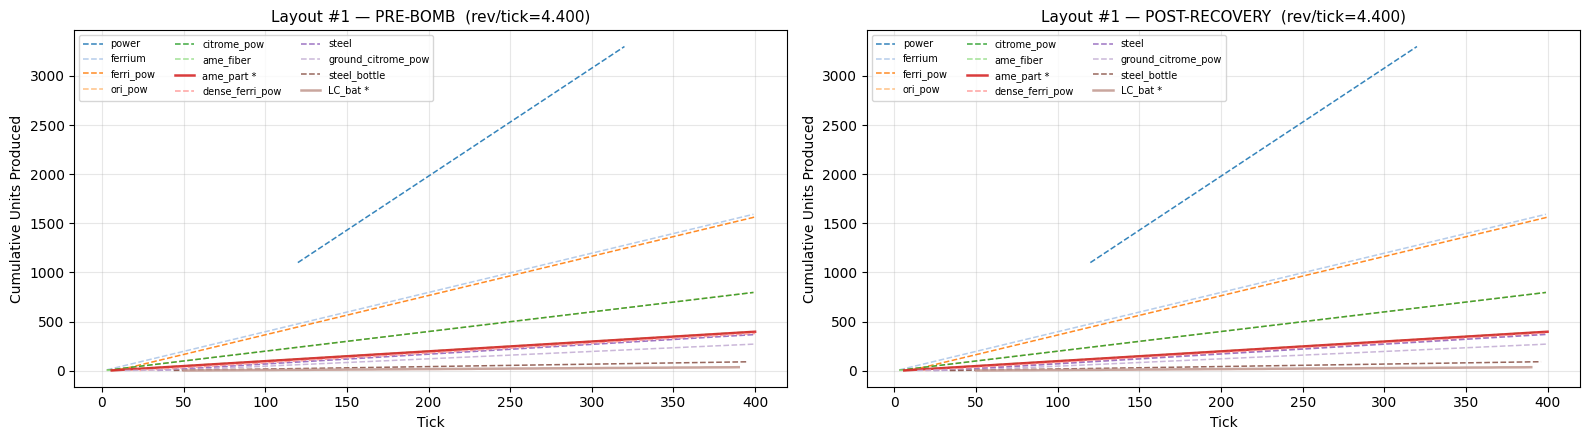

  Saved v4_sim_throughput_layout_1.png

--- Layout #2 ---
  [SIM] Layout #2 PRE-BOMB: 70 machines, 68 belts, 28 boundary-fed machines
  No equilibrium within 400 ticks
  [SIM] Layout #2 PRE-BOMB: ran=55/70 machines, starved at end=9, sim revenue/tick=9.500, eq_tick=None
  [SIM] Layout #2 PRE-BOMB: live_fraction=96% (needs >= 50% for equilibrium)
  PRODUCTION — Layout #2 PRE-BOMB: analytic vs simulated   [mode=net]
    material           made/t   used/t    net/t  unit    rev/t   share    sim/t   ratio
    SC_bat             0.1030   0.0000   0.1030    30   3.0900  47.0%   0.0044     4%
    steel_part         1.0000   0.0100   0.9900     3   2.9700  45.1%   0.0167     2%
    ferri_part         1.5250   1.0300   0.4950     1   0.4950   7.5%   0.1333     9%
    HC_bat             0.0010   0.0001   0.0009    27   0.0243   0.4%   0.0000     0%
    dense_ferri_pow    1.0000   1.0000   0.0000     0   0.0000   0.0%   0.0178     2%
    dense_ori_pow      0.0150   0.0150   0.0000     0   0.0000  

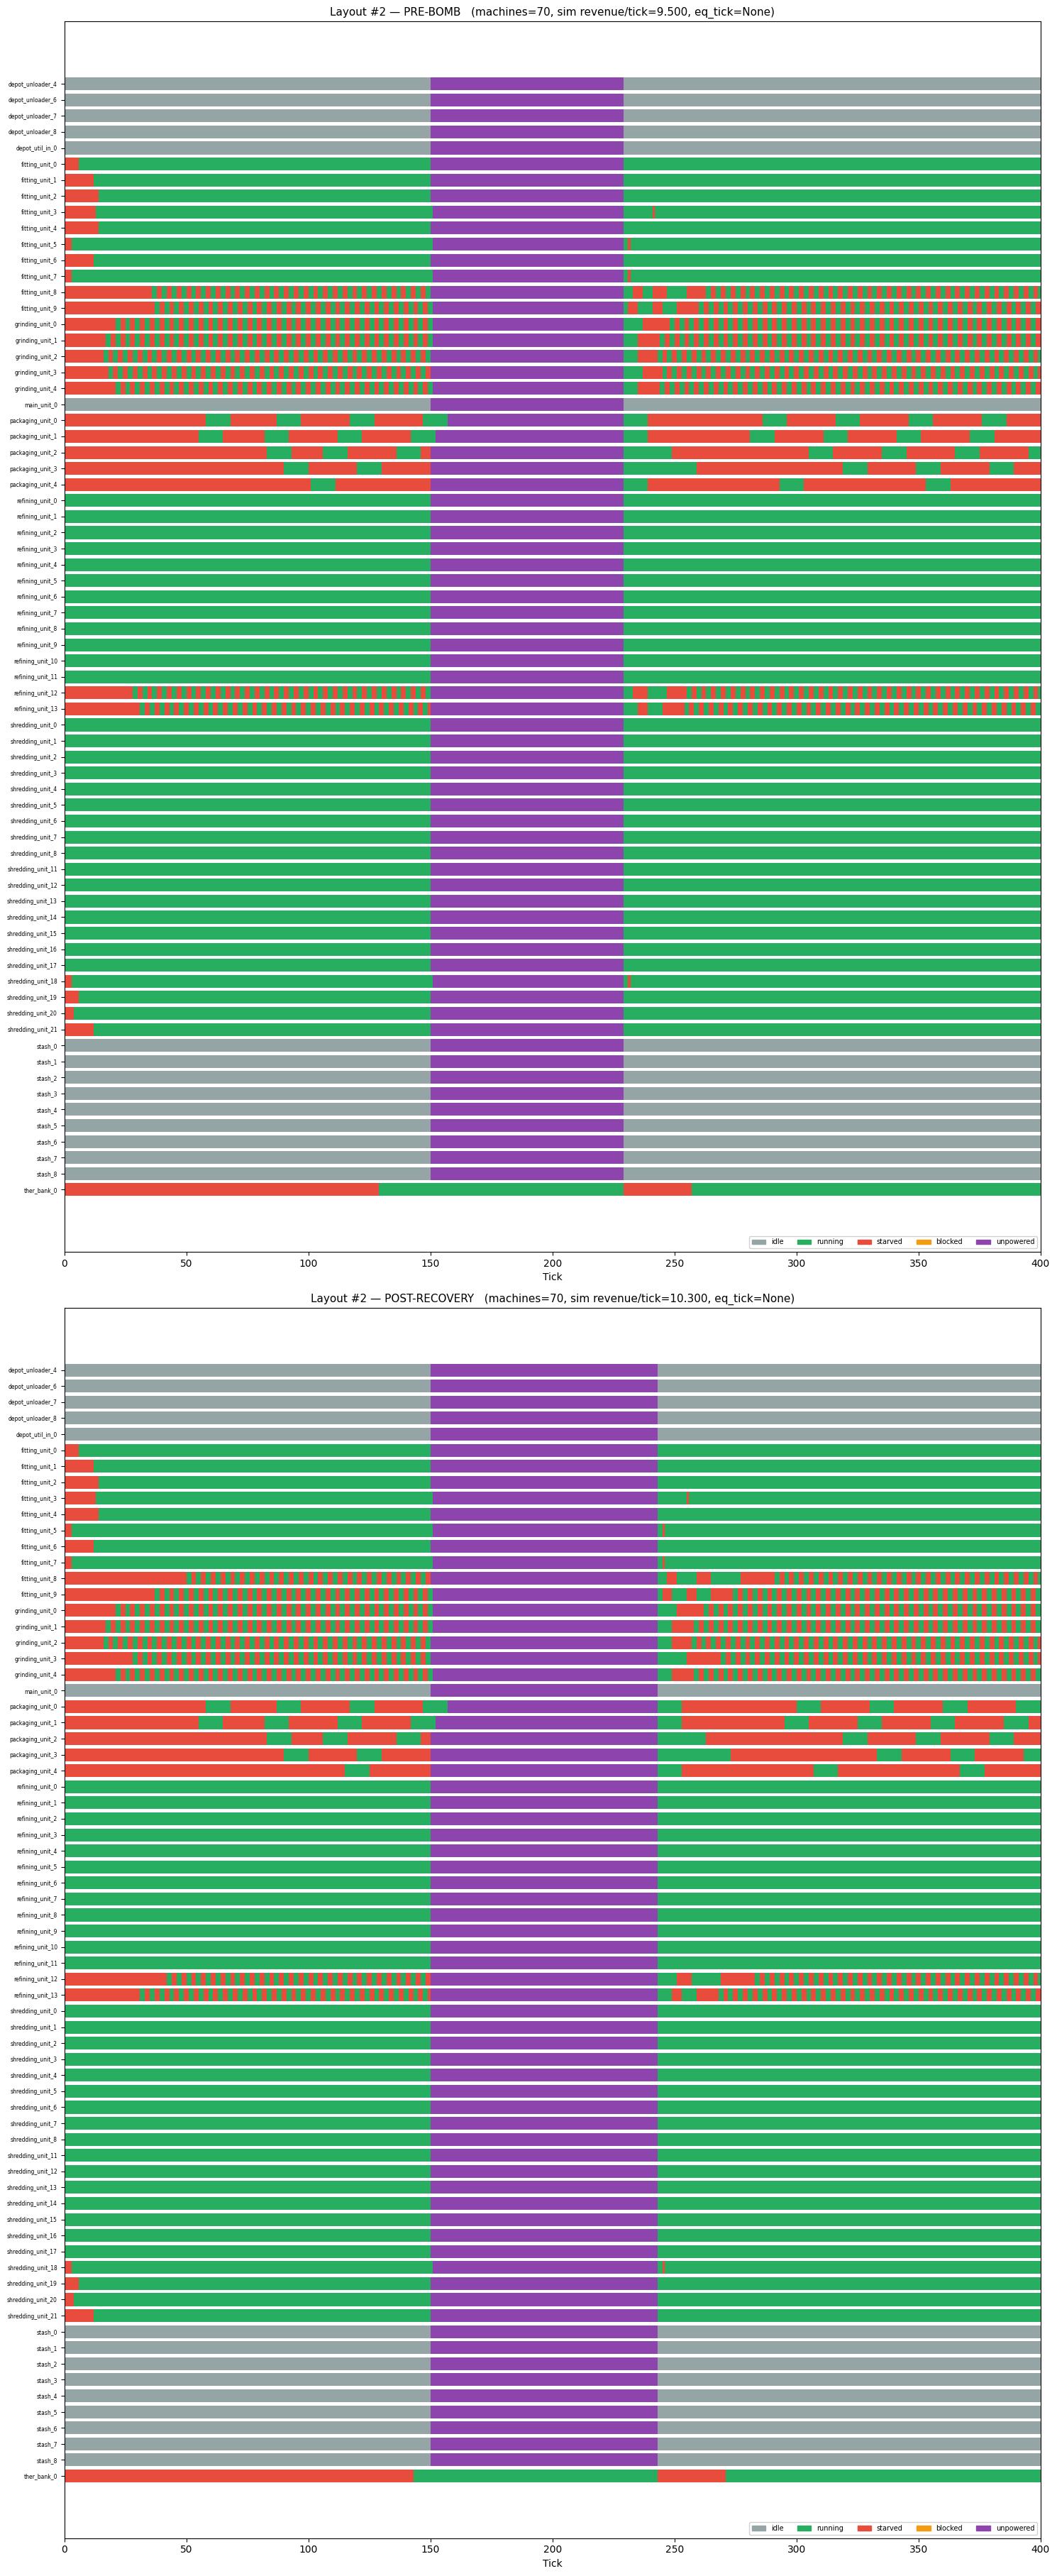

  Saved v4_sim_gantt_layout_2.png


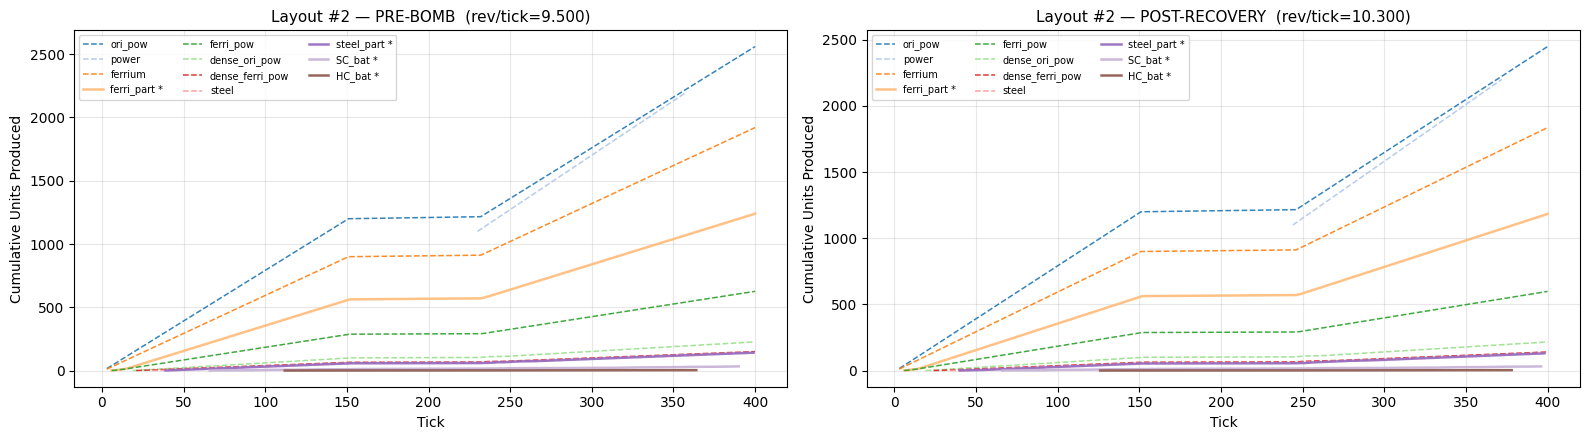

  Saved v4_sim_throughput_layout_2.png

--- Layout #3 ---
  [SIM] Layout #3 PRE-BOMB: 56 machines, 60 belts, 19 boundary-fed machines
  No equilibrium within 400 ticks
  [SIM] Layout #3 PRE-BOMB: ran=37/56 machines, starved at end=12, sim revenue/tick=4.333, eq_tick=None
  [SIM] Layout #3 PRE-BOMB: live_fraction=82% (needs >= 50% for equilibrium)
  PRODUCTION — Layout #3 PRE-BOMB: analytic vs simulated   [mode=net]
    material           made/t   used/t    net/t  unit    rev/t   share    sim/t   ratio
    SC_bat             0.1000   0.0000   0.1000    30   3.0000  97.7%   0.0011     1%
    buck_cap_A         0.0010   0.0000   0.0010    70   0.0700   2.3%   0.0011   111%
    HC_bat             0.0000   0.0100  -0.0100    27   0.0000   0.0%   0.0000       —
    buck_pow           0.0200   0.0200   0.0000     0   0.0000   0.0%   0.0667   333%
    buckflower         2.0000   1.0100   0.9900     0   0.0000   0.0%   0.0000     0%
    buckflower_seed    2.0000   1.0000   1.0000     0   0.0000

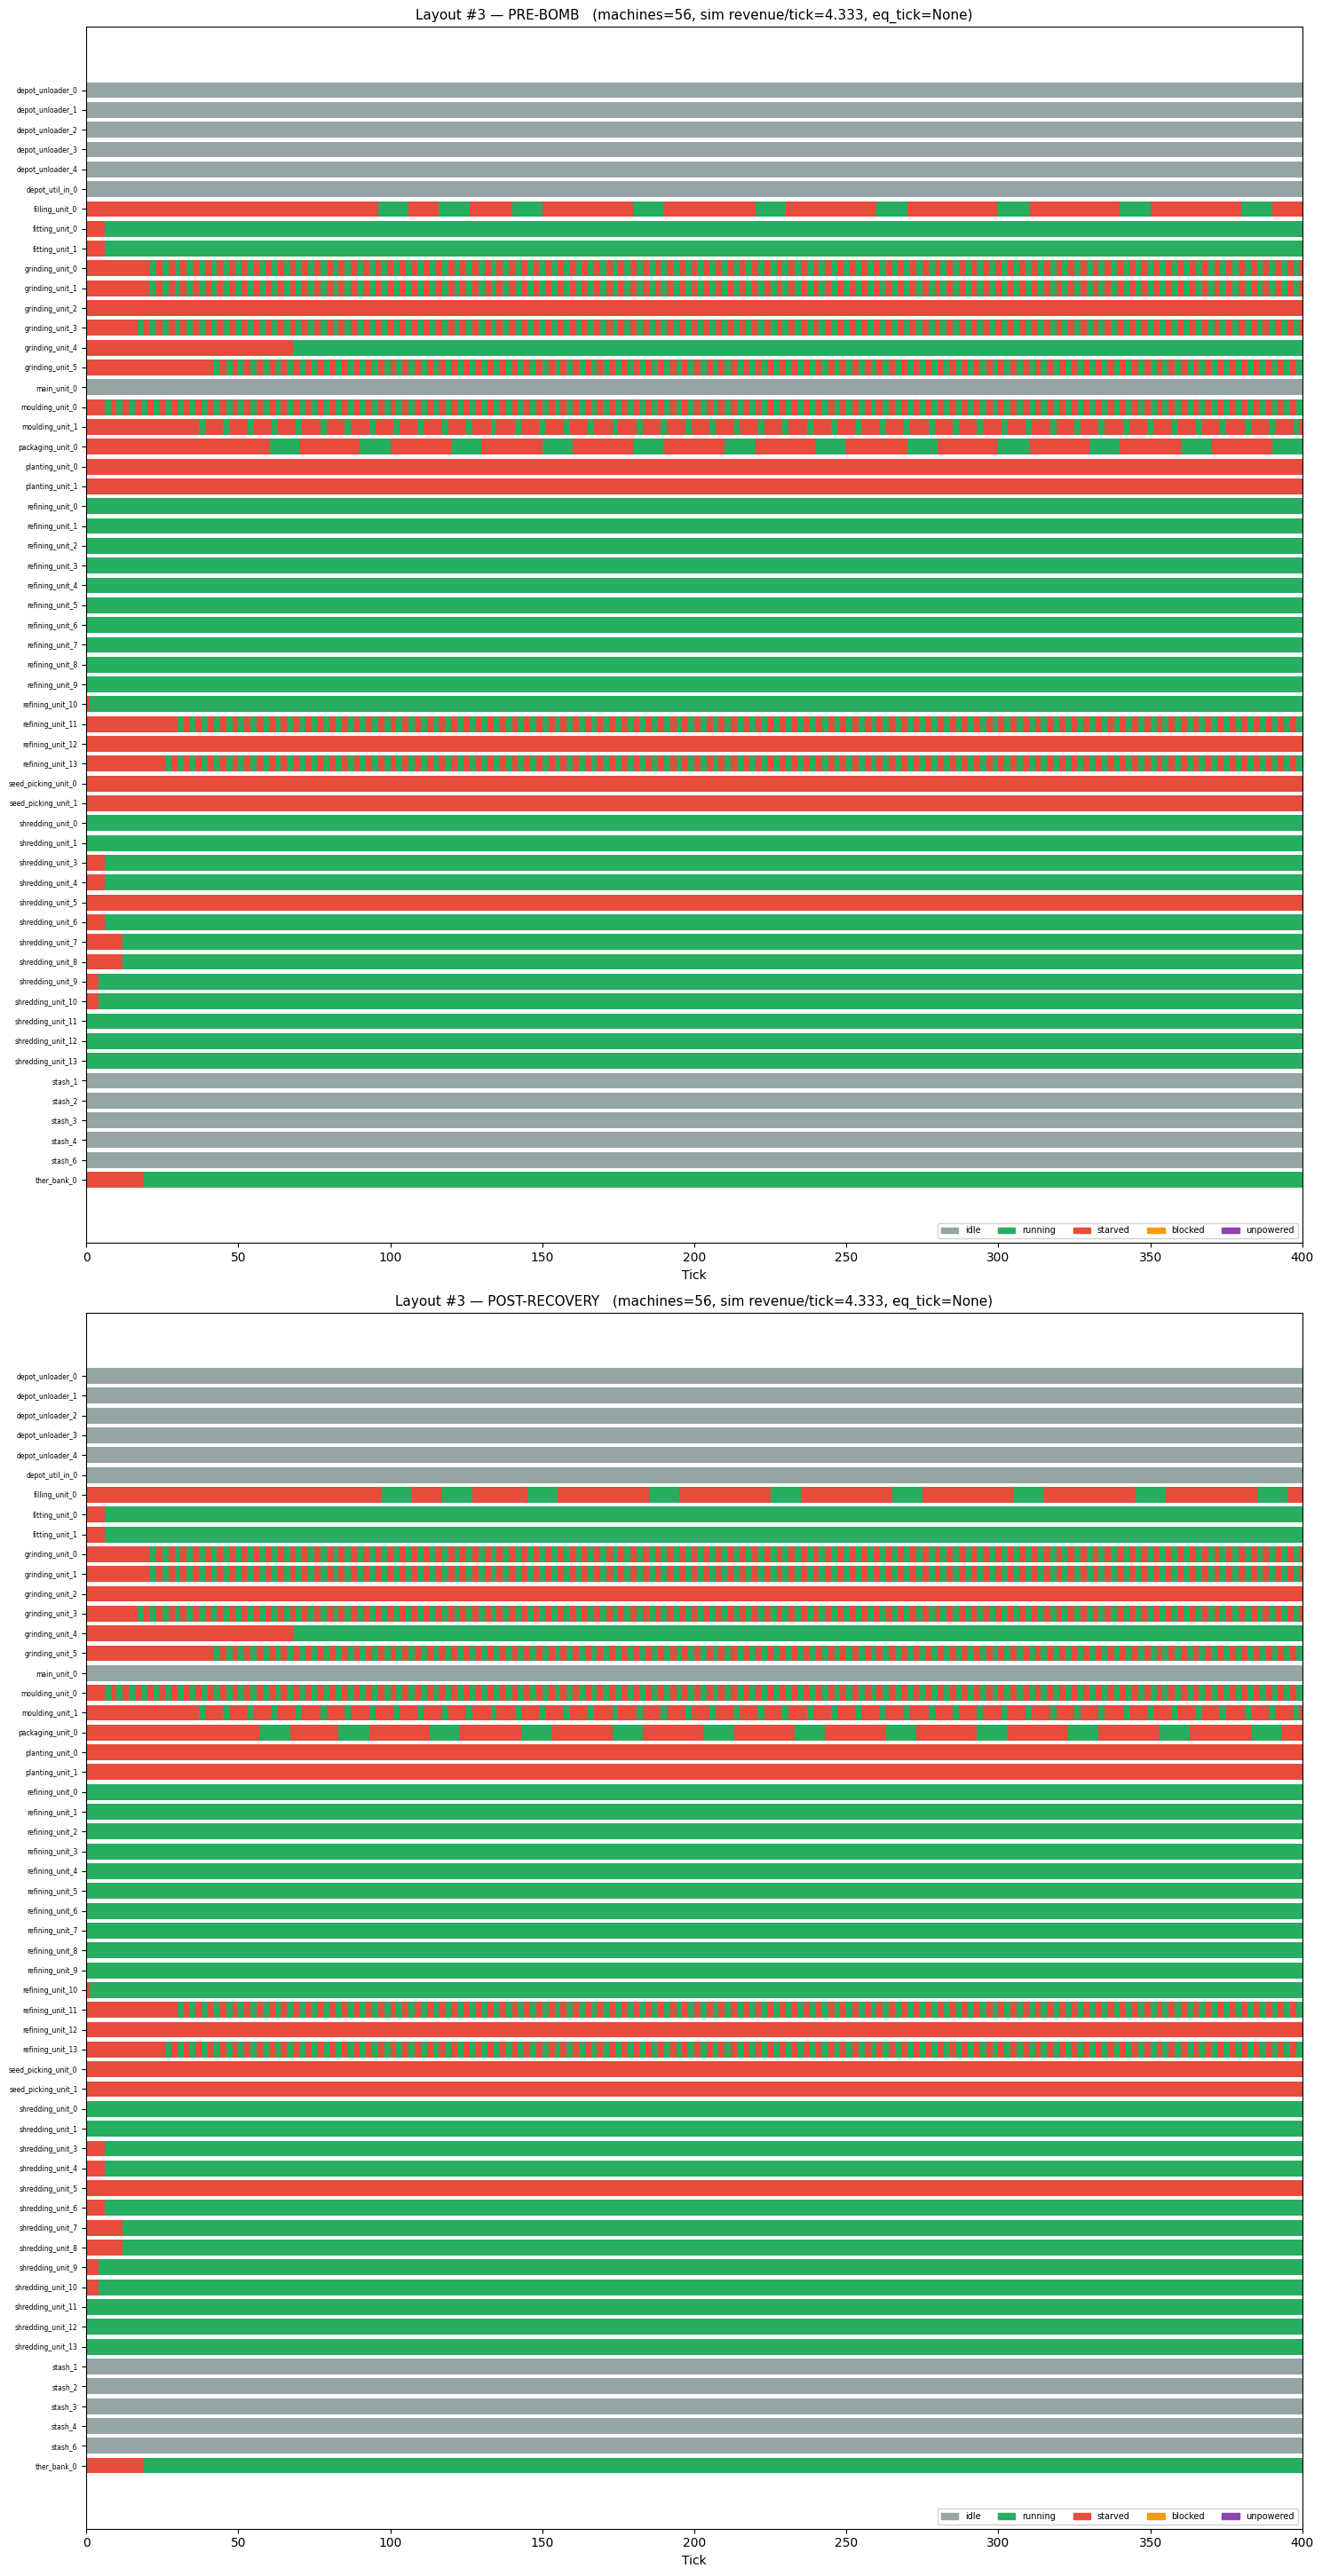

  Saved v4_sim_gantt_layout_3.png


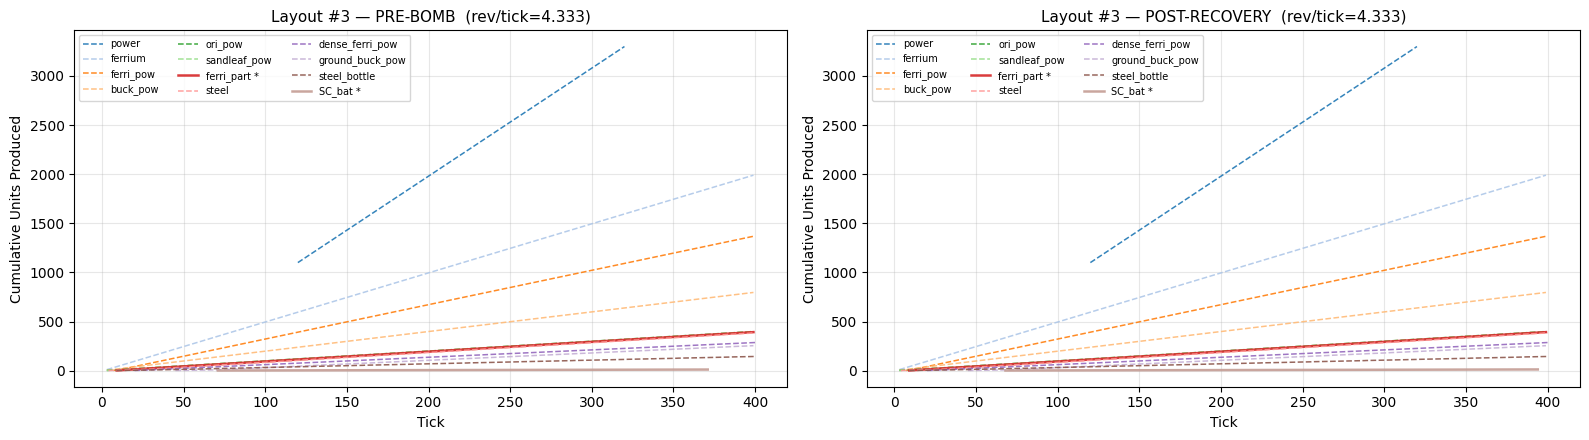

  Saved v4_sim_throughput_layout_3.png

--- Layout #4 ---
  [SIM] Layout #4 PRE-BOMB: 52 machines, 50 belts, 17 boundary-fed machines
  No equilibrium within 400 ticks
  [SIM] Layout #4 PRE-BOMB: ran=40/52 machines, starved at end=11, sim revenue/tick=4.333, eq_tick=None
  [SIM] Layout #4 PRE-BOMB: live_fraction=93% (needs >= 50% for equilibrium)
  PRODUCTION — Layout #4 PRE-BOMB: analytic vs simulated   [mode=net]
    material           made/t   used/t    net/t  unit    rev/t   share    sim/t   ratio
    ferri_part         0.5050   0.0100   0.4950     1   0.4950  83.2%   0.0333     7%
    can_cit_A          0.0010   0.0000   0.0010    70   0.0700  11.8%   0.0011   111%
    SC_bat             0.0010   0.0000   0.0010    30   0.0300   5.0%   0.0011   111%
    HC_bat             0.0000   0.0100  -0.0100    27   0.0000   0.0%   0.0000       —
    citrome            2.0000   1.5050   0.4950     0   0.0000   0.0%   0.0000     0%
    citrome_pow        1.0100   1.0100   0.0000     0   0.0000

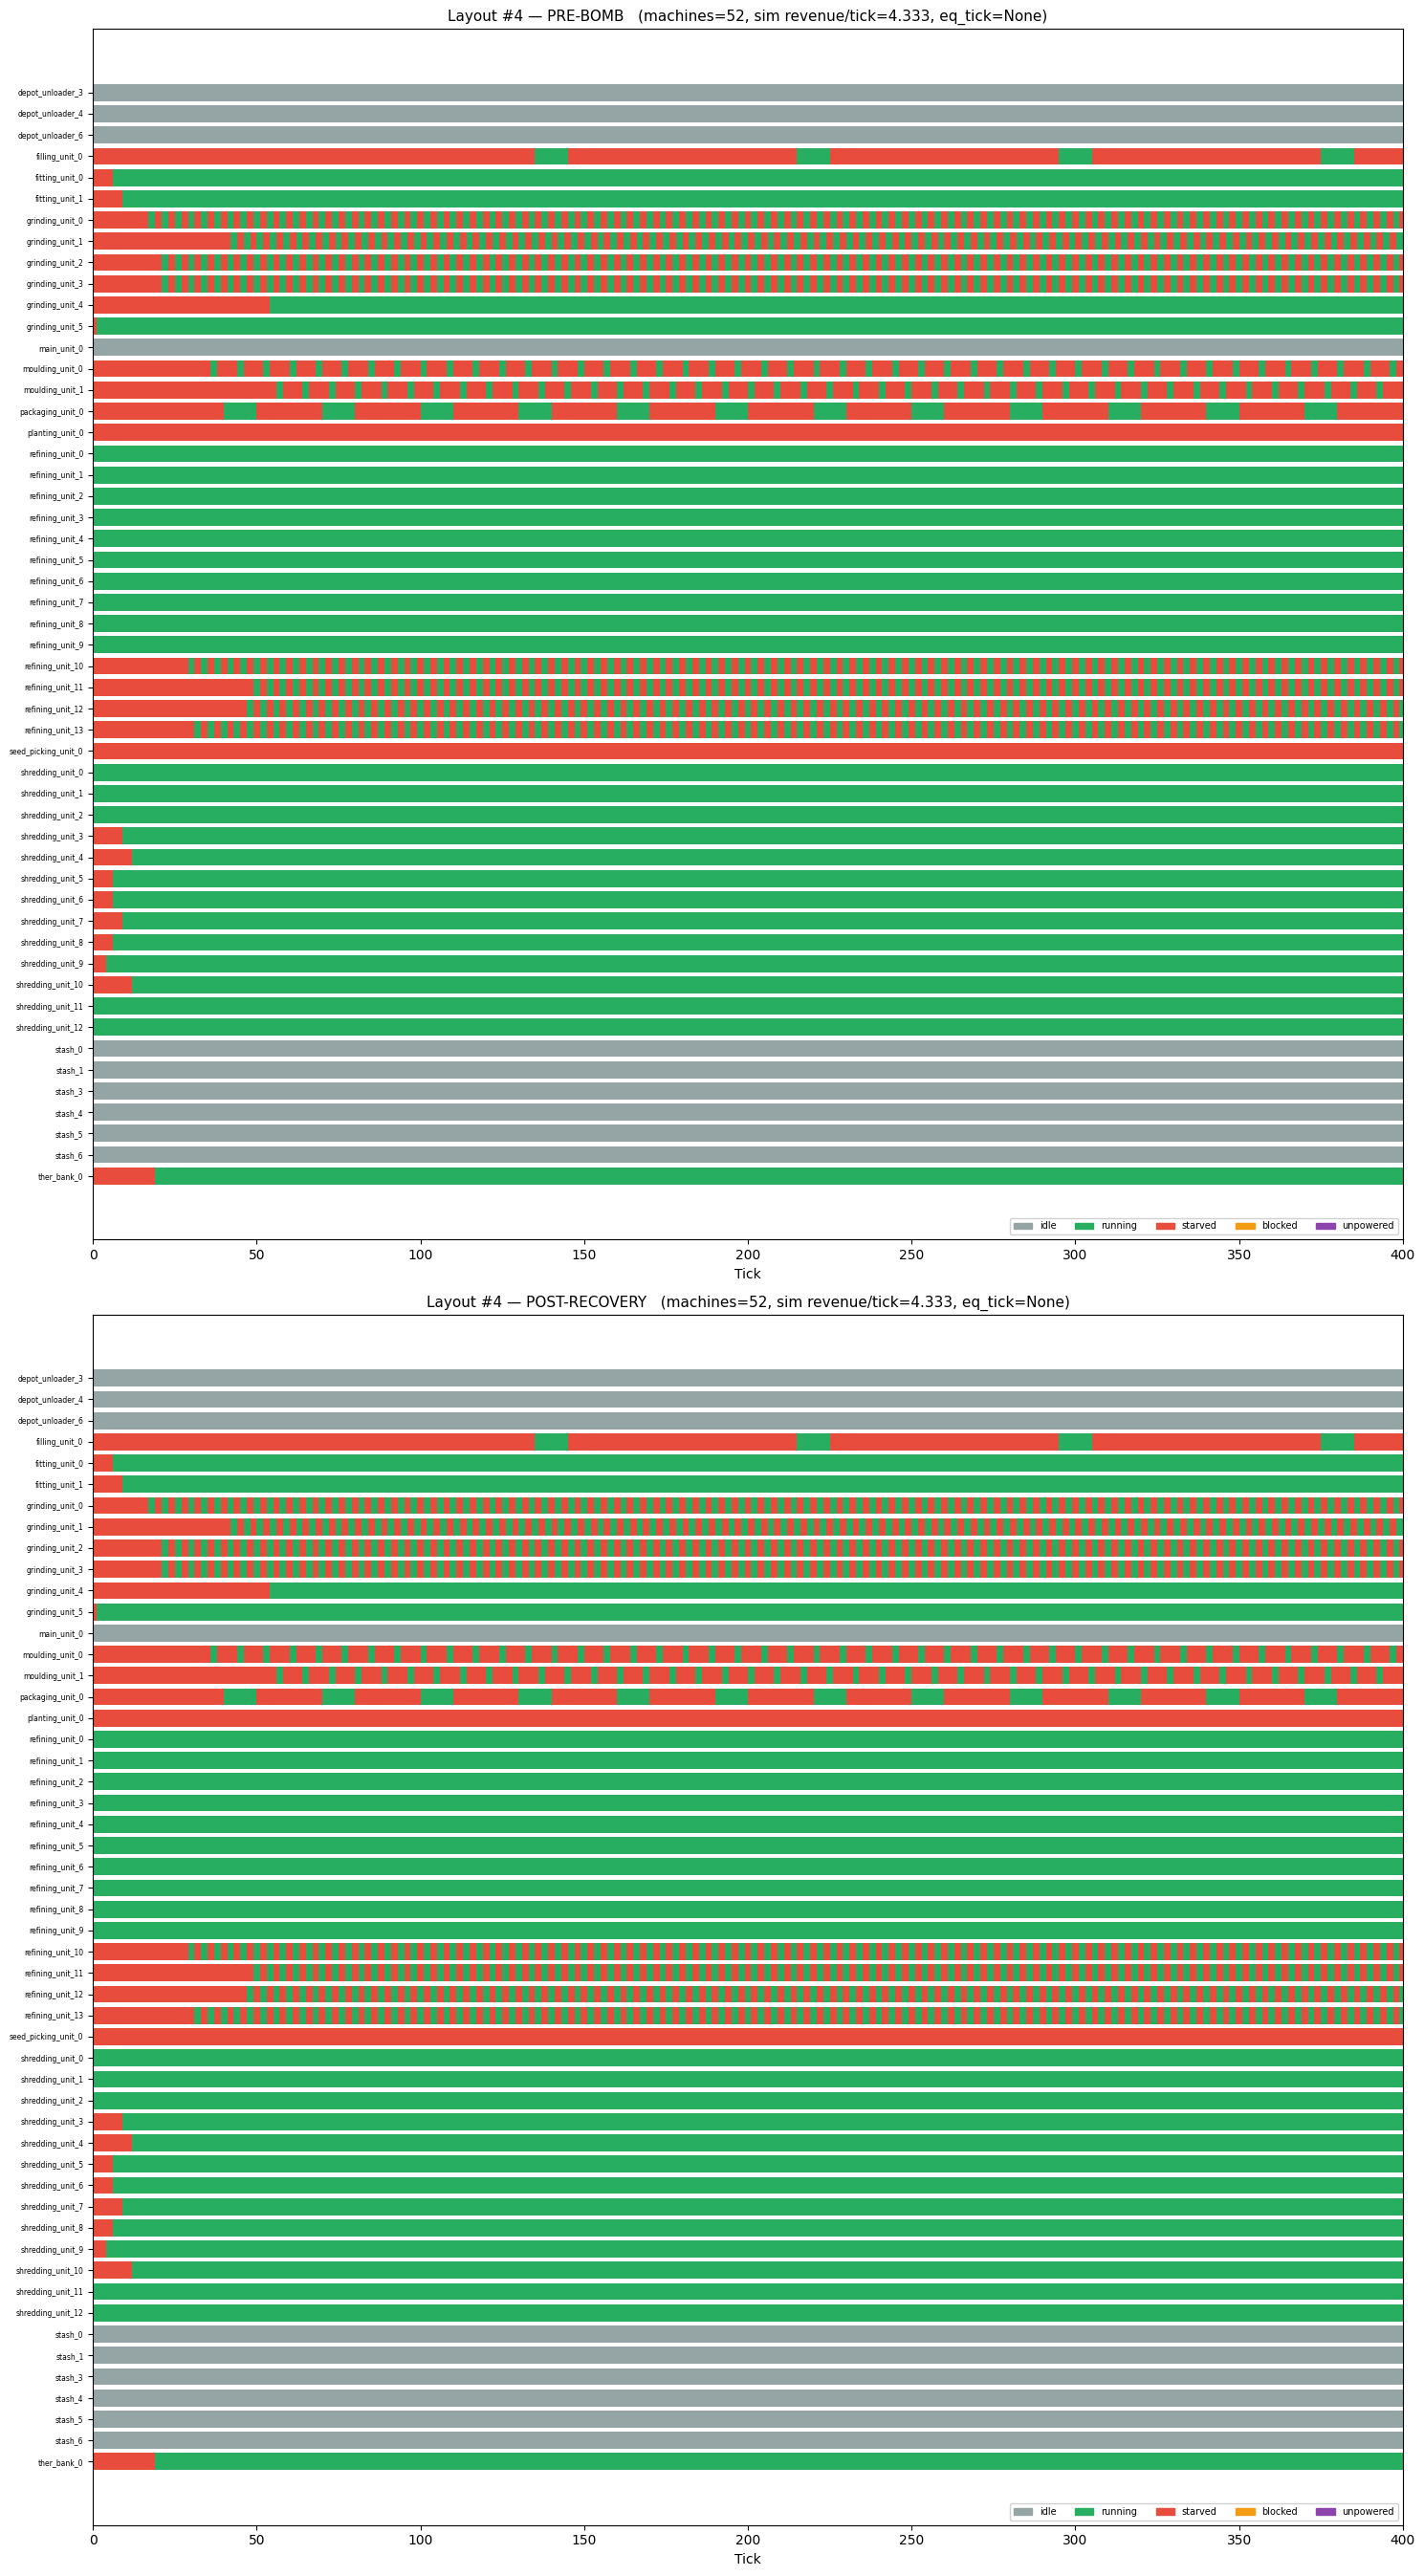

  Saved v4_sim_gantt_layout_4.png


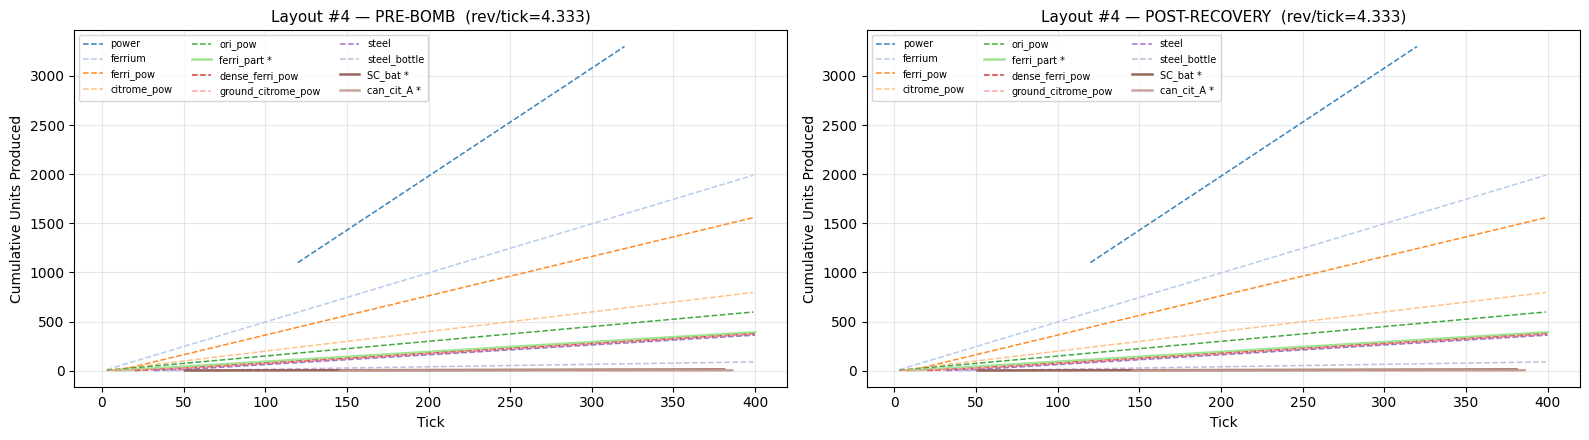

  Saved v4_sim_throughput_layout_4.png

--- Layout #5 ---
  [SIM] Layout #5 PRE-BOMB: 58 machines, 60 belts, 26 boundary-fed machines
  No equilibrium within 400 ticks
  [SIM] Layout #5 PRE-BOMB: ran=45/58 machines, starved at end=8, sim revenue/tick=10.467, eq_tick=None
  [SIM] Layout #5 PRE-BOMB: live_fraction=94% (needs >= 50% for equilibrium)
  PRODUCTION — Layout #5 PRE-BOMB: analytic vs simulated   [mode=net]
    material           made/t   used/t    net/t  unit    rev/t   share    sim/t   ratio
    SC_bat             0.2020   0.0000   0.2020    30   6.0600  58.5%   0.0044     2%
    can_cit_B          0.1000   0.0000   0.1000    27   2.7000  26.1%   0.0011     1%
    LC_bat             0.1000   0.0000   0.1000    16   1.6000  15.4%   0.0022     2%
    HC_bat             0.0000   0.0001  -0.0001    27   0.0000   0.0%   0.0000       —
    ame_fiber          0.5000   0.5000   0.0000     0   0.0000   0.0%   0.0167     3%
    ame_ore            0.0000   0.5000  -0.5000     0   0.0000

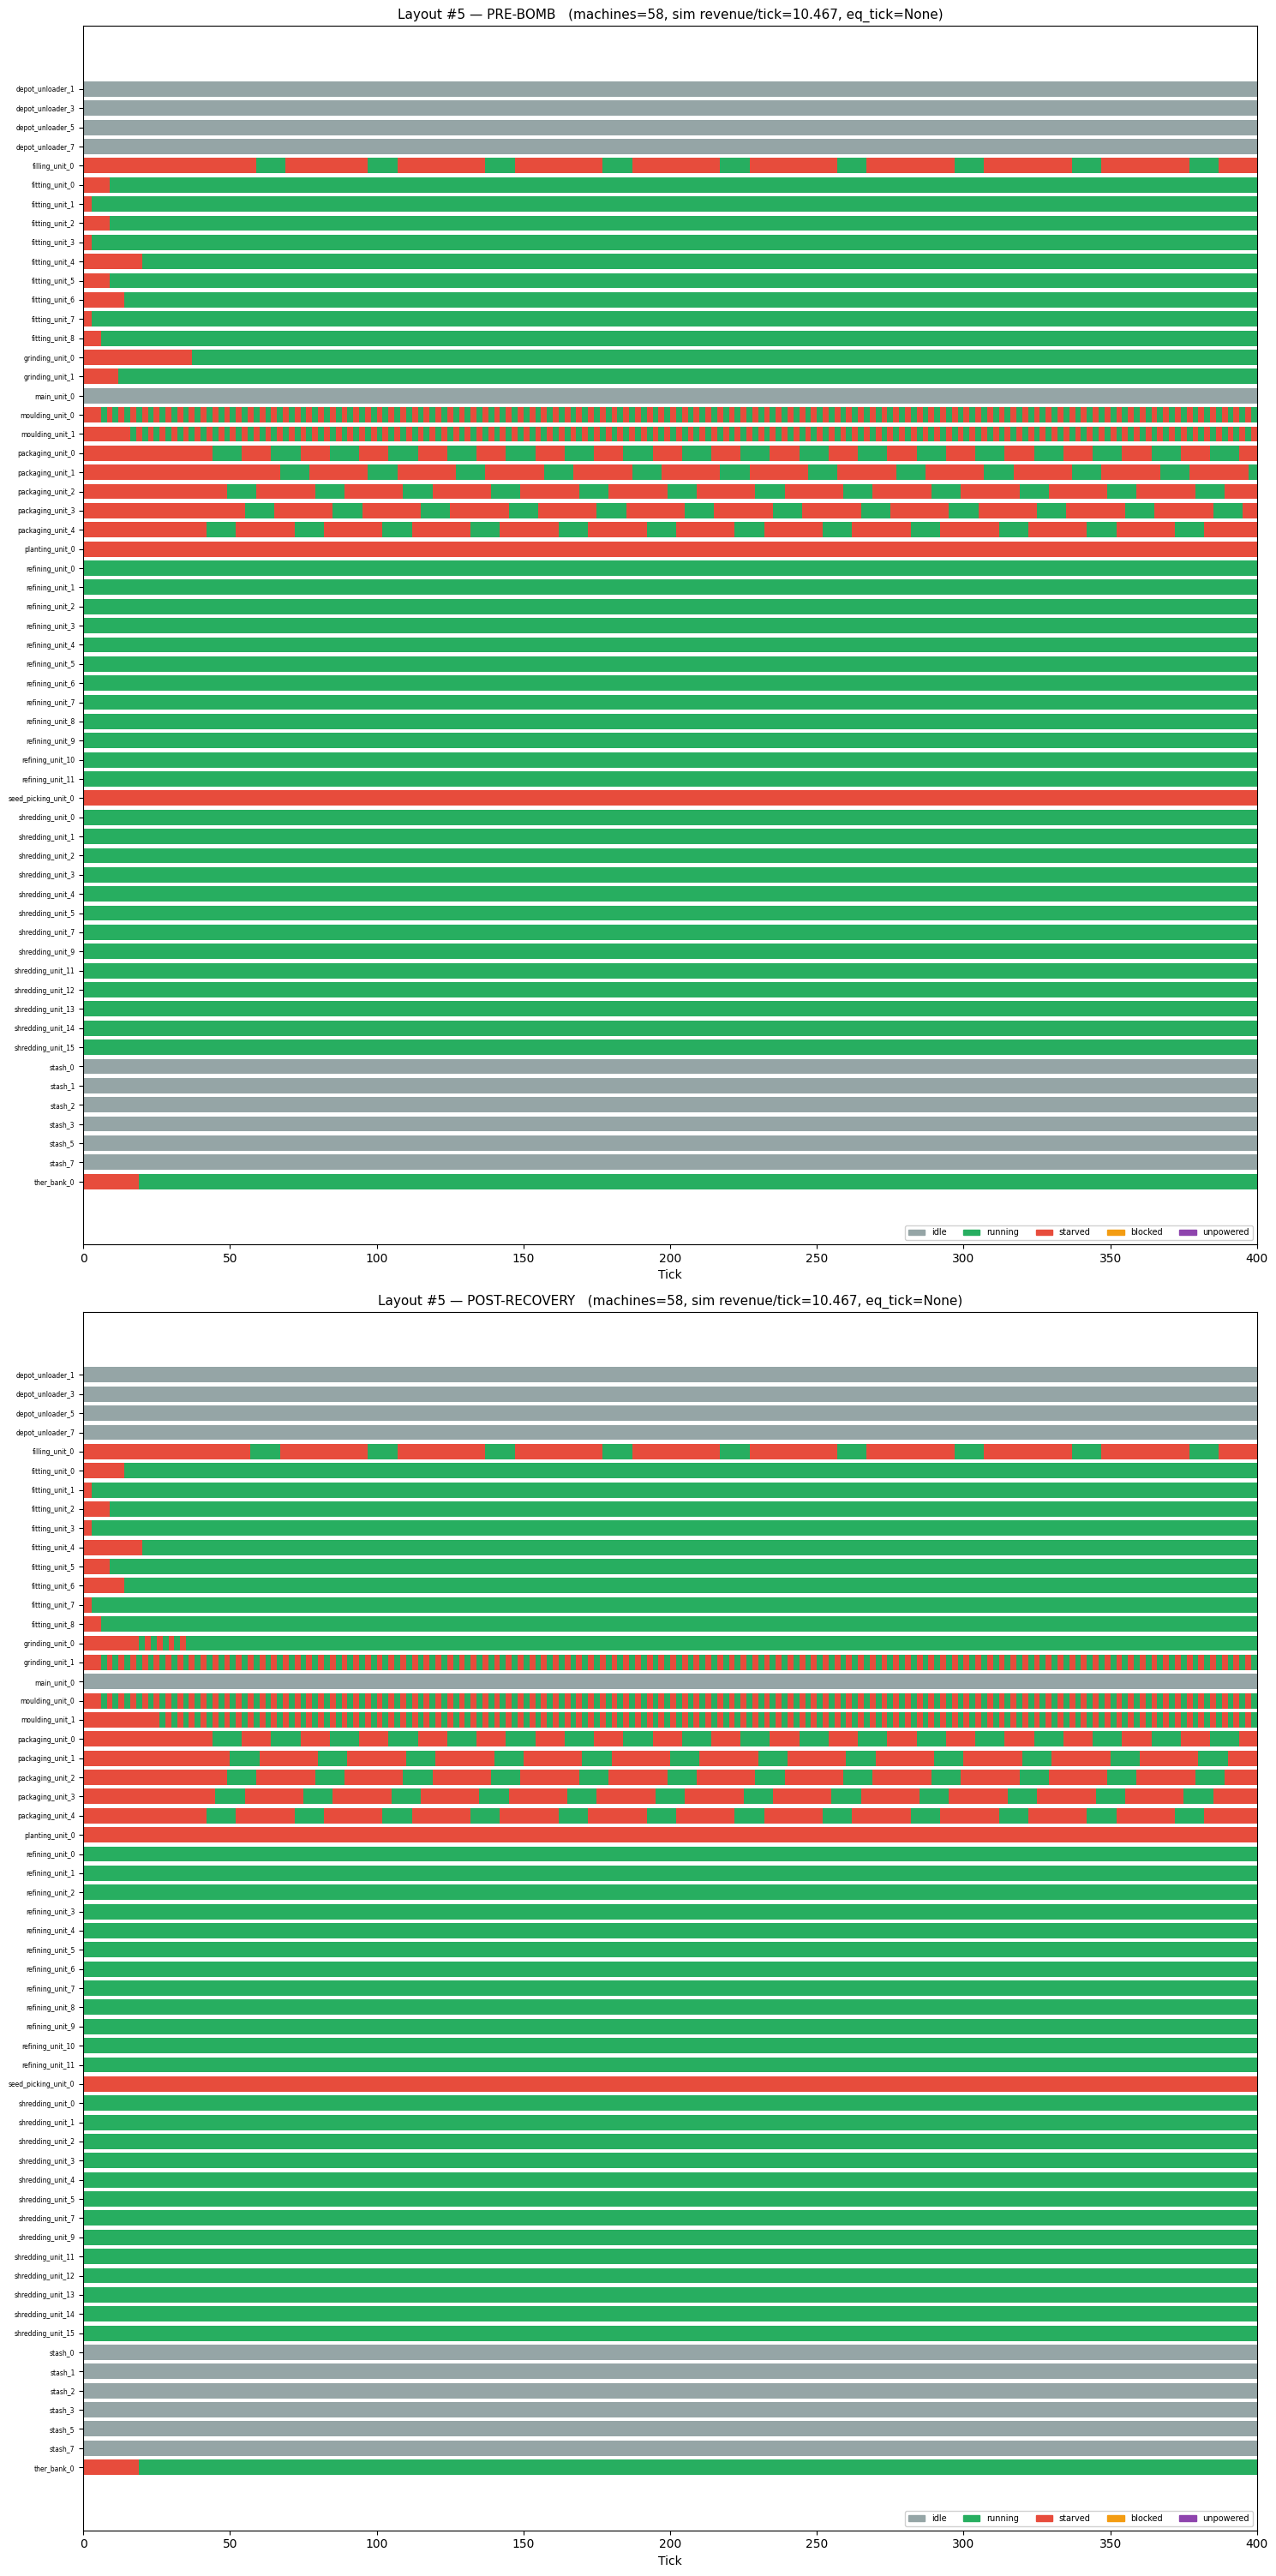

  Saved v4_sim_gantt_layout_5.png


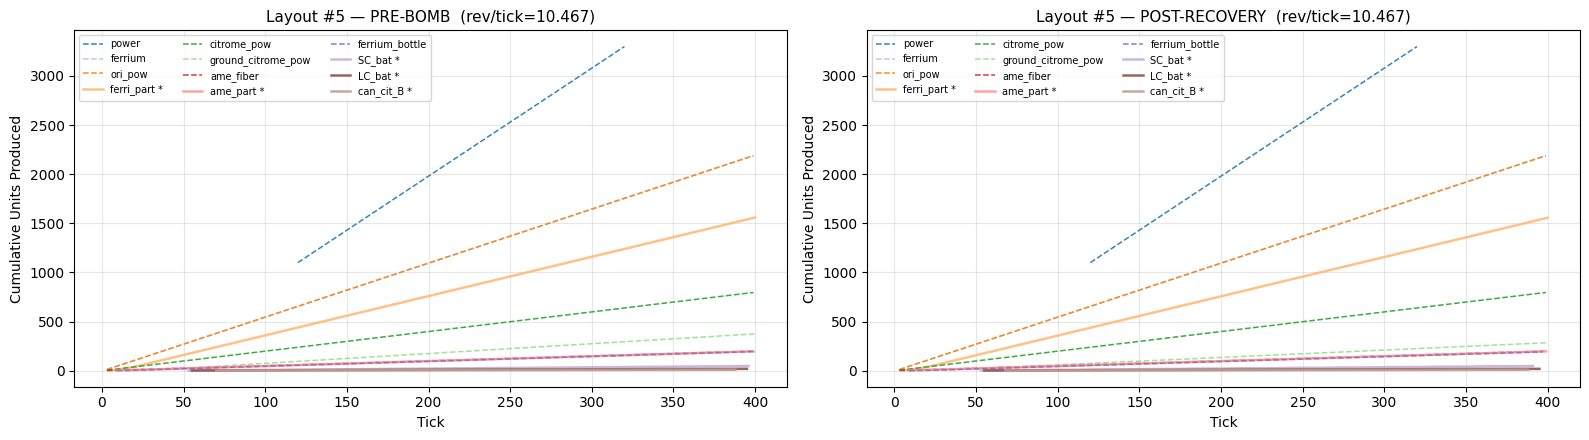

  Saved v4_sim_throughput_layout_5.png

PHASE 5 SUMMARY — analytical estimate vs simulated throughput
Layout      AnalyticRate  SimRev/tick  PostRev/tick  SimRegret  Gate2 static  Gate2 sim   cause      
------------------------------------------------------------------------------------------------
Layout #1        10.0828       4.4000        4.4000     0.0000          True      False   starvation 
Layout #2         6.5166       9.5000       10.3000     0.0000          True      False   none       
Layout #3         3.0370       4.3333        4.3333     0.0000          True      False   none       
Layout #4         0.5911       4.3333        4.3333     0.0000          True      False   none       
Layout #5        10.0944      10.4667       10.4667     0.0000          True      False   none       

[!] 5/5 layouts where the static Gate 2 (_chain_time <= 300) and the simulation DISAGREE ON TIMING.
    The static gate is a critical-path estimate over the flow DAG; it
    assumes every 

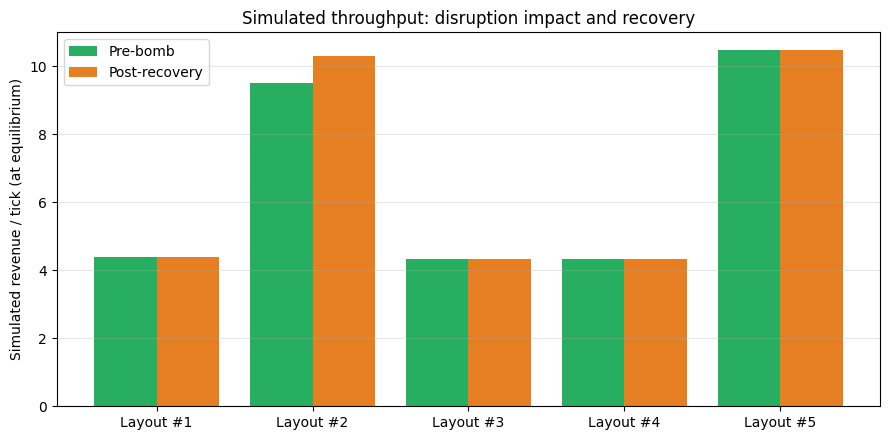

Saved v4_sim_regret_summary.png


In [ ]:
# ─── PHASE 5: DISCRETE-TIME SIMULATION — PRE-BOMB vs POST-RECOVERY ─────────────
print("=" * 70)
print("PHASE 5: Discrete-time simulation — production timeline & throughput")
print("=" * 70)

sim_top     = refined[:CFG.SIM_TOP_N]
sim_records = []

for idx, (ind, result, terminal_rate, total_genes, chromo, main_feas) in enumerate(sim_top):
    label      = f"Layout #{idx + 1}"
    zpf_result = getattr(ind, "_flp_cache", {}).get("zpf")
    print(f"\n--- {label} ---")

    pre_engine,  pre_eq  = simulate_layout(result, label=f"{label} PRE-BOMB")
    post_engine, post_eq = (None, None)
    if zpf_result is not None:
        post_engine, post_eq = simulate_layout(zpf_result, label=f"{label} POST-RECOVERY")

    pre_rev  = pre_engine.simulated_revenue_per_tick(window=CFG.SIM_EQ_WINDOW)
    post_rev = (post_engine.simulated_revenue_per_tick(window=CFG.SIM_EQ_WINDOW)
                if post_engine is not None else 0.0)

    # Regret measured on SIMULATED throughput rather than the analytical rate.
    sim_regret = max(0.0, pre_rev - post_rev)

    # Why the simulation produced what it produced. The old agreement check
    # compared equilibrium TIMING only, so a layout with an analytic rate of
    # 7.0000 and 0.000 simulated revenue/tick was reported as agreeing.
    pre_diag  = diagnose_simulation(pre_engine, pre_eq, terminal_rate)
    post_diag = (diagnose_simulation(post_engine, post_eq, terminal_rate)
                 if post_engine is not None else None)
    print("  [SIM] " + explain_simulation(pre_diag, f"{label} PRE-BOMB: "))
    if post_diag is not None:
        print("  [SIM] " + explain_simulation(post_diag, f"{label} POST-RECOVERY: "))

    sim_records.append(dict(
        label=label, idx=idx,
        pre_engine=pre_engine, pre_eq=pre_eq, pre_rev=pre_rev,
        post_engine=post_engine, post_eq=post_eq, post_rev=post_rev,
        sim_regret=sim_regret,
        static_chain_time=result["chain_time"],
        static_sustain_ok=result["chain_time"] <= SIM_EQ_MAX_TICKS,
        sim_sustain_ok=(pre_eq is not None and pre_eq <= SIM_EQ_MAX_TICKS),
        analytic_rate=terminal_rate,
        pre_diag=pre_diag, post_diag=post_diag,
    ))

    # ── Paired Gantt: pre-bomb above, post-recovery below ─────────────────────
    if HAS_MPL:
        engines = [(pre_engine, pre_eq, "PRE-BOMB", pre_rev)]
        if post_engine is not None:
            engines.append((post_engine, post_eq, "POST-RECOVERY", post_rev))

        rows = max(len(e.states) for e, _, _, _ in engines)
        fig, axes_g = plt.subplots(len(engines), 1, squeeze=False,
                                   figsize=(15, max(3.5, rows * 0.26) * len(engines)))
        for row_i, (eng, eq, tag, rev) in enumerate(engines):
            plot_gantt(eng, eq_tick=eq, ax=axes_g[row_i][0],
                       max_ticks=CFG.SIM_MAX_TICKS,
                       title=f"{label} — {tag}   "
                             f"(machines={len(eng.states)}, "
                             f"sim revenue/tick={rev:.3f}, eq_tick={eq})")
        plt.tight_layout()
        plt.savefig(f"v4_sim_gantt_layout_{idx + 1}.png", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"  Saved v4_sim_gantt_layout_{idx + 1}.png")

        # ── Paired throughput curves ─────────────────────────────────────────
        fig, axes_t = plt.subplots(1, len(engines), squeeze=False,
                                   figsize=(8 * len(engines), 4.5))
        for col_i, (eng, eq, tag, rev) in enumerate(engines):
            plot_throughput(eng, ax=axes_t[0][col_i],
                            title=f"{label} — {tag}  (rev/tick={rev:.3f})")
        plt.tight_layout()
        plt.savefig(f"v4_sim_throughput_layout_{idx + 1}.png", dpi=150, bbox_inches="tight")
        plt.show()
        print(f"  Saved v4_sim_throughput_layout_{idx + 1}.png")


# ── Summary: analytical model vs simulation ───────────────────────────────────
print("\n" + "=" * 78)
print("PHASE 5 SUMMARY — analytical estimate vs simulated throughput")
print("=" * 78)
print(f"{'Layout':10s} {'AnalyticRate':>13s} {'SimRev/tick':>12s} "
      f"{'PostRev/tick':>13s} {'SimRegret':>10s} {'Gate2 static':>13s} {'Gate2 sim':>10s} "
      f"  {'cause':<11s}")
print("-" * 96)
for r in sim_records:
    print(f"{r['label']:10s} {r['analytic_rate']:13.4f} {r['pre_rev']:12.4f} "
          f"{r['post_rev']:13.4f} {r['sim_regret']:10.4f} "
          f"{str(r['static_sustain_ok']):>13s} {str(r['sim_sustain_ok']):>10s} "
          f"  {r['pre_diag']['cause']:<11s}")

# ── Check 1: equilibrium TIMING (what this section used to check, alone) ──────
disagree = [r for r in sim_records if r["static_sustain_ok"] != r["sim_sustain_ok"]]
if disagree:
    print(f"\n[!] {len(disagree)}/{len(sim_records)} layouts where the static Gate 2 "
          f"(_chain_time <= {SIM_EQ_MAX_TICKS}) and the simulation DISAGREE ON TIMING.")
    print("    The static gate is a critical-path estimate over the flow DAG; it")
    print("    assumes every machine is fed. The simulation does not. Where they")
    print("    differ, trust the simulation and treat the static gate as optimistic.")
else:
    print(f"\n[OK] Static Gate 2 and the simulation agree on TIMING for every layout.")

# ── Check 2: THROUGHPUT. This is the one that was missing. ───────────────────
# A layout can pass the timing check and produce nothing whatsoever: observed on
# a real run, analytic rates of 7.0000 and 6.2000 against 0.000 simulated
# revenue/tick, reported as "[OK] ... agree on every simulated layout".
dead  = [r for r in sim_records if not r["pre_diag"]["produced"]]
short = [r for r in sim_records
         if r["pre_diag"]["produced"] and r["pre_diag"]["cause"] != "none"]

if dead:
    print(f"\n[!!] {len(dead)}/{len(sim_records)} layouts produce NOTHING in simulation "
          f"while the analytical model reports a positive rate.")
    print("     The analytical rate is revenue x feasibility over the flow DAG. It")
    print("     assumes every routed flow delivers and every machine is powered;")
    print("     neither is checked. Where the simulation produces nothing, the")
    print("     analytical rate for that layout is not a throughput estimate.")
    for r in dead:
        print(f"     - {r['label']}: analytic {r['analytic_rate']:.4f} -> sim 0.000  |  "
              + explain_simulation(r["pre_diag"]))
# Reported separately rather than chained onto the block above: a run can hold
# BOTH a layout that produces nothing and one that merely under-produces, and an
# elif hides the second -- the same class of omission as the original defect.
if short:
    print(f"\n[!] {len(short)}/{len(sim_records)} layouts produce, but below "
          f"{CFG.SIM_AGREE_FRACTION:.0%} of the analytical rate.")
    for r in short:
        print(f"     - {r['label']}: " + explain_simulation(r["pre_diag"]))
if not dead and not short:
    print("[OK] Every simulated layout reaches at least "
          f"{CFG.SIM_AGREE_FRACTION:.0%} of its analytical rate.")

# ── Cause breakdown, so two different failures are never conflated ────────────
_causes = {}
for r in sim_records:
    _causes[r["pre_diag"]["cause"]] = _causes.get(r["pre_diag"]["cause"], 0) + 1
if set(_causes) - {"none"}:
    print("\n  Failure causes across the simulated layouts: "
          + ", ".join(f"{k}={v}" for k, v in sorted(_causes.items()) if k != "none"))
    print("    power      -- the factory cannot pay its own draw (see P5 in the register)")
    print("    starvation -- machines are fed too slowly, or never run at all")
    print("    no-supply  -- nothing is injected at the boundary")
    print("    throughput -- produces, but well under the analytical claim")

if HAS_MPL and sim_records:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    xs   = range(len(sim_records))
    ax.bar([x - 0.2 for x in xs], [r["pre_rev"] for r in sim_records],
           width=0.4, label="Pre-bomb", color="#27AE60")
    ax.bar([x + 0.2 for x in xs], [r["post_rev"] for r in sim_records],
           width=0.4, label="Post-recovery", color="#E67E22")
    ax.set_xticks(list(xs))
    ax.set_xticklabels([r["label"] for r in sim_records])
    ax.set_ylabel("Simulated revenue / tick (at equilibrium)")
    ax.set_title("Simulated throughput: disruption impact and recovery")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig("v4_sim_regret_summary.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved v4_sim_regret_summary.png")
